# Group T, mini-project 1: HCP language task (story vs math)
Single subject, single run. Part 1: structural and functional preprocessing, GLM. Part 2: temporal K-means (variant 3).

Before starting: download the data from Moodle (files too large for GitHub) and place it so that it matches the structure below.

**Data folder structure**

```code
T_miniproject_1
    /T_code.ipynb
    /data
        /T1
            /T1w.nii.gz
        /fMRI
            /tfMRI_LANGUAGE_LR
                /tfMRI_LANGUAGE_LR_task_onsets.csv
                /tfMRI_LANGUAGE_LR.nii.gz
        /derivatives          <- created by this notebook (outputs + figures)
```

Requirements: FSL (`FSLDIR` set, tools in the PATH) and the Python packages `nilearn`, `nibabel`, `antspyx`, `scikit-learn`.
Run the cells in order (about 15 minutes in total).

| Part | Sections |
|---|---|
| 1-1 Structural preprocessing | 1a skull-stripping, 1b segmentation, 1c registration to MNI |
| 1-2 Functional preprocessing | 2a motion correction, 2b smoothing, 2c anatomical-functional alignment |
| 1-3 GLM | 3a design matrix, 3b regressor correlation, 3c GLM, 3d story - math contrast, 3e networks, 3f semantic regions |
| 2 Temporal K-means | 1 clustering, 2 choice of K and centroid maps, 3 clusters vs GLM regressors |

In [1]:
import os
import os.path as op
import shutil
import subprocess
import urllib.request

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage
from nilearn import datasets, image, plotting, signal
from nilearn.glm import threshold_stats_img
from nilearn.glm.first_level import FirstLevelModel, make_first_level_design_matrix
from nilearn.plotting import plot_design_matrix
from nilearn.reporting import get_clusters_table
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Data folder, relative to this notebook: works on every machine without editing
data_dir = op.abspath("data")
out_dir = op.join(data_dir, "derivatives")
out_anatomical_dir = op.join(out_dir, "anat")     # part 1-1
out_func_dir = op.join(out_dir, "func")            # part 1-2
glm_dir = op.join(out_dir, "glm")                  # part 1-3
atlas_dir = op.join(out_dir, "atlases")
km_dir = op.join(out_dir, "kmeans")                # part 2

t1_path = op.join(data_dir, "T1", "T1w.nii.gz") # original structural image
fig_dir = op.join(out_dir, "figures") # folder for the saved figures
for d in (out_anatomical_dir, out_func_dir, glm_dir, atlas_dir, km_dir, fig_dir):
    os.makedirs(d, exist_ok=True)                   # create output folders (no error if they exist)
FIG_DPI = 300                                       # enough for the PDF report (1000 dpi gave 9000 px images)


# FSL environment
## REQUIRES FSL download (https://fsl.fmrib.ox.ac.uk/fsl/docs/install/index.html)
fsldir = os.environ.get("FSLDIR", op.expanduser("~/fsl"))  # FSL install folder (this is the default, change if needed)
os.environ["FSLDIR"] = fsldir                       # make sure FSL tools can find their files
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"            # FSL writes .nii.gz files
os.environ["PATH"] = os.pathsep.join([op.join(fsldir, "bin"), op.join(fsldir, "share", "fsl", "bin"), os.environ["PATH"]])

# MNI152 templates
mni_head = op.join(fsldir, "data", "standard", "MNI152_T1_2mm.nii.gz")        # whole-head template
mni_brain = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain.nii.gz")  # skull-stripped template

# Colours shared by the figures
STORY_COLOR, MATH_COLOR = "#2a78d6", "#eb6834"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#b3302f"])

assert op.exists(t1_path), f"T1w image not found: {t1_path}"
assert op.exists(mni_head), f"MNI template not found: {mni_head}"
assert op.exists(mni_brain), f"MNI template not found: {mni_brain}"
assert shutil.which("bet"), f"FSL tools not found in the PATH (FSLDIR={fsldir})"

print("All good. T1w:", op.relpath(t1_path))
print("FSL directory:", fsldir)

All good. T1w: data/T1/T1w.nii.gz
FSL directory: /Users/valentinmarbach/miniconda3/envs/neural_signal


# Part 1-1. Structural preprocessing

## 1a. Skull-stripping (FSL BET)

**Purpose.** Remove the skull, scalp and neck. Their intensities would bias the next steps: FAST models the voxel intensities as a mixture of tissues, and the registration maximises an intensity similarity with a skull-stripped template.

**Parameters.** `-R` (robust brain-centre estimation) and `-f 0.3`, more permissive than the default 0.5. The annex below compares the two: 0.5 removes ~59 mL more at the base of the brain, so we keep 0.3 to avoid cutting brain tissue, at the cost of a few small non-brain islands (orbit / sinus region).

In [2]:
brain_prefix = op.join(out_anatomical_dir, "T1w_brain") # BET output name (without extension)
brain = brain_prefix + ".nii.gz"                        # skull-stripped brain image
mask = brain_prefix + "_mask.nii.gz"                    # binary brain mask

# FSL BET: -R robust centre estimation, -f 0.3 threshold (see justification above), -m save mask
subprocess.run(["bet", t1_path, brain_prefix, "-R", "-f", "0.3", "-m"], check=True)

CompletedProcess(args=['bet', 'data/T1/T1w.nii.gz', 'data/derivatives/anat/T1w_brain', '-R', '-f', '0.3', '-m'], returncode=0)

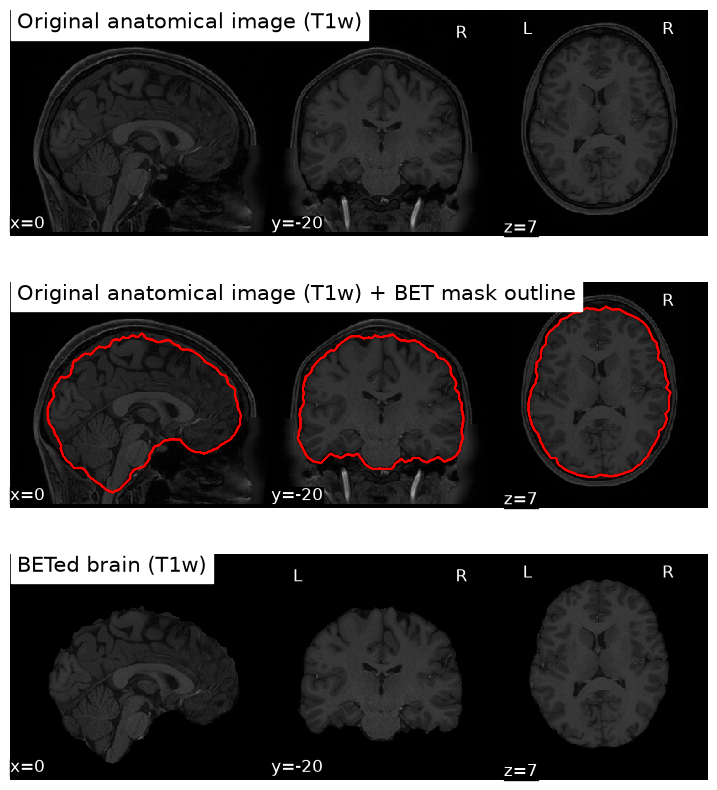

In [3]:
# Plotting results: same slices in every row, so that the rows can be compared
CUT = (0, -20, 7)
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

# subplot 1: original T1w
plotting.plot_anat(t1_path, axes=axs[0], cut_coords=CUT, draw_cross=False,
                   title="Original anatomical image (T1w)", colorbar=False)

# subplot 2: original T1w with the brain mask outline in red (to check the extraction quality)
ax = plotting.plot_anat(t1_path, axes=axs[1], cut_coords=CUT, draw_cross=False,
                        title="Original anatomical image (T1w) + BET mask outline", colorbar=False)
ax.add_contours(mask, colors="r", linewidths=1)  # draw the mask boundary

# subplot 3: betted brain
plotting.plot_anat(brain, axes=axs[2], cut_coords=CUT, draw_cross=False,
                   title="BETed brain (T1w)", colorbar=False)

fig.savefig(op.join(fig_dir, "1_skull_stripping_BET.png"), dpi=FIG_DPI)
plt.show()

### Annex: choice of the BET threshold `-f`

The same BET run with the default `-f 0.5`. Both outlines are drawn on a low slice, where the two masks differ most.

Brain mask volume  -f 0.3: 1379 mL   -f 0.5: 1322 mL


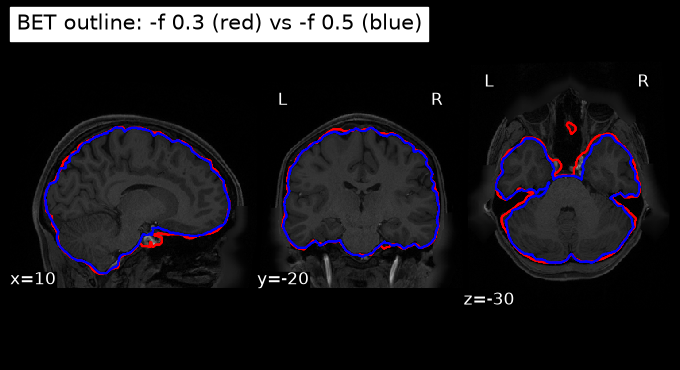

In [4]:
bet05_prefix = op.join(out_anatomical_dir, "T1w_brain_f05")
mask05 = bet05_prefix + "_mask.nii.gz"
subprocess.run(["bet", t1_path, bet05_prefix, "-R", "-f", "0.5", "-m"], check=True)

def volume_ml(img_path):
    """Volume (mL) of the non-zero voxels of an image."""
    img = nib.load(img_path)
    return (img.get_fdata() > 0).sum() * np.prod(img.header.get_zooms()[:3]) / 1000

print(f"Brain mask volume  -f 0.3: {volume_ml(mask):.0f} mL   -f 0.5: {volume_ml(mask05):.0f} mL")

d = plotting.plot_anat(t1_path, cut_coords=(10, -20, -30), draw_cross=False, colorbar=False,
                       title="BET outline: -f 0.3 (red) vs -f 0.5 (blue)")
d.add_contours(mask, colors="r", linewidths=1)
d.add_contours(mask05, colors="b", linewidths=1)
d.savefig(op.join(fig_dir, "annex_BET_threshold.png"), dpi=FIG_DPI)
plt.show()

## 1b. Tissue segmentation (FSL FAST)

**Purpose.** Separate grey matter, white matter and CSF. This checks the anatomy (tissue volumes printed below) and gives a grey-matter mask of where the BOLD signal comes from.

In [5]:
# Run FAST (takes a few minutes)
fast_prefix = op.join(out_anatomical_dir, "T1w_brain_fast")
seg = fast_prefix + "_seg.nii.gz"       # hard labels: 1 = CSF, 2 = GM, 3 = WM

# FAST: -t 1 = T1 image, -n 3 = three tissue classes
subprocess.run(["fast", "-t", "1", "-n", "3", "-o", fast_prefix, brain], check=True)

# Tissue volumes from the partial-volume maps (pve_k = fraction of tissue k in each voxel)
voxel_ml = np.prod(nib.load(brain).header.get_zooms()[:3]) / 1000
for k, name in enumerate(["CSF", "Grey matter", "White matter"]):
    pve = nib.load(f"{fast_prefix}_pve_{k}.nii.gz").get_fdata()
    print(f"{name:13s}: {pve.sum() * voxel_ml:4.0f} mL")

CSF          :  229 mL
Grey matter  :  654 mL
White matter :  496 mL


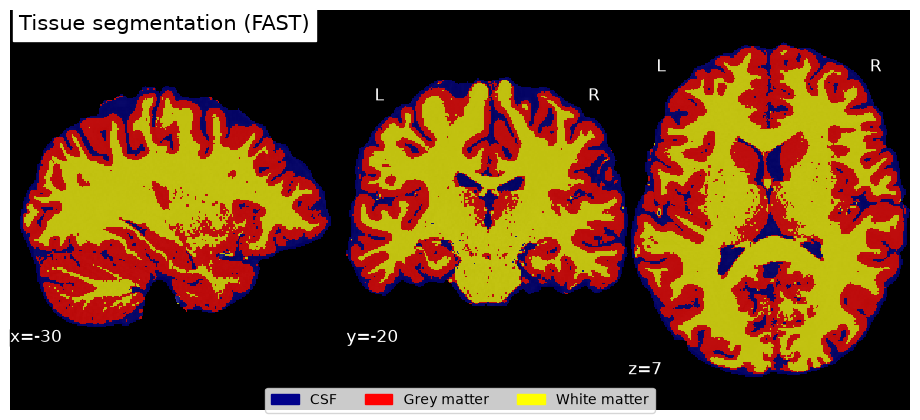

In [6]:
# Plotting the segmentation results
# x = -30: a lateral sagittal slice shows the cortical ribbon (x = 0 falls in the interhemispheric fissure)
fig = plt.figure(figsize=(9, 4))

plotting.plot_roi(seg, bg_img=brain, cut_coords=(-30, -20, 7), vmin=1, vmax=3,
                  cmap=ListedColormap(["darkblue", "red", "yellow"]),
                  alpha=0.7, colorbar=False, draw_cross=False, figure=fig,
                  title="Tissue segmentation (FAST)")
fig.legend(handles=[Patch(color="darkblue", label="CSF"),
                    Patch(color="red", label="Grey matter"),
                    Patch(color="yellow", label="White matter")],
           loc="lower center", ncol=3)

fig.savefig(op.join(fig_dir, "2_segmentation.png"), dpi=FIG_DPI)
plt.show()

## 1c. Registration to MNI space

**Purpose.** Bring the subject into a standard space, so that the activations can be read with the coordinates and atlases of the literature (3e-3f). HCP provides the fMRI already normalised to MNI (*MNINonLinear*), so the T1 must be in the same space.

1. **FLIRT, linear, 12 DOF.** The scale factors of the matrix (~1.08 / 1.12 / 1.18) show that the subject's brain is smaller than the template, which a rigid 6-DOF transform could not absorb.
2. **ANTs SyN, non-linear (as in lab 2).** The HCP fMRI was normalised non-linearly, so the T1 must be too, otherwise the ventricles and sulci would not match (2c). SyN improves the overlap of the brain with the template (Dice 0.89 with FLIRT, 0.94 with SyN), although the intensity correlation is slightly lower (0.85 vs 0.81).

The SyN transform is also applied to the FAST segmentation (nearest neighbour, to keep integer labels). The native T1 is already AC-PC aligned by HCP, which is why the "before" panel is already roughly centred.

In [7]:
affine_mat = op.join(out_anatomical_dir, "T1_to_MNI_flirt.mat") # linear transformation matrix (from FLIRT)
brain_flirt = op.join(out_anatomical_dir, "T1w_brain_MNI_FLIRT.nii.gz")

# FLIRT: linear registration (defaults written explicitly: 12 DOF affine, correlation ratio cost)
subprocess.run(["flirt", "-in", brain, "-ref", mni_brain, "-out", brain_flirt, "-omat", affine_mat,
                "-dof", "12", "-cost", "corratio"], check=True)
print("FLIRT matrix:\n", np.loadtxt(affine_mat).round(3))

# ANTs SyN: non-linear registration (lab 2), initialised by an affine step inside ants.registration
import ants
brain_syn = op.join(out_anatomical_dir, "T1w_brain_MNI_SyN.nii.gz")
seg_mni = op.join(out_anatomical_dir, "T1w_brain_fast_seg_MNI_SyN.nii.gz")

mni_ants = ants.image_read(mni_brain)
tx = ants.registration(fixed=mni_ants, moving=ants.image_read(brain), type_of_transform="SyN")
ants.image_write(tx["warpedmovout"], brain_syn)

# same transform applied to the tissue labels (nearest neighbour keeps the labels 1/2/3)
seg_warped = ants.apply_transforms(fixed=mni_ants, moving=ants.image_read(seg),
                                   transformlist=tx["fwdtransforms"], interpolator="nearestNeighbor")
ants.image_write(seg_warped, seg_mni)


def match_with_mni(img_path):
    """Intensity correlation and Dice of the brain masks between an image and the MNI brain template."""
    x = nib.load(img_path).get_fdata()
    m = nib.load(mni_brain).get_fdata()
    union = (x > 0) | (m > 0)
    corr = np.corrcoef(x[union], m[union])[0, 1]
    dice = 2 * ((x > 0) & (m > 0)).sum() / ((x > 0).sum() + (m > 0).sum())
    return corr, dice

reg_scores = {name: match_with_mni(p) for name, p in [("FLIRT", brain_flirt), ("SyN", brain_syn)]}
for name, (corr, dice) in reg_scores.items():
    print(f"{name:5s}: correlation with MNI = {corr:.3f}   Dice = {dice:.3f}")

FLIRT matrix:
 [[ 1.0830e+00 -1.5000e-02  2.0000e-03 -6.2430e+00]
 [ 2.3000e-02  1.1230e+00 -6.0000e-03 -1.6255e+01]
 [-1.3000e-02 -5.0000e-03  1.1810e+00 -9.4730e+00]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]]


FLIRT: correlation with MNI = 0.854   Dice = 0.894
SyN  : correlation with MNI = 0.810   Dice = 0.942


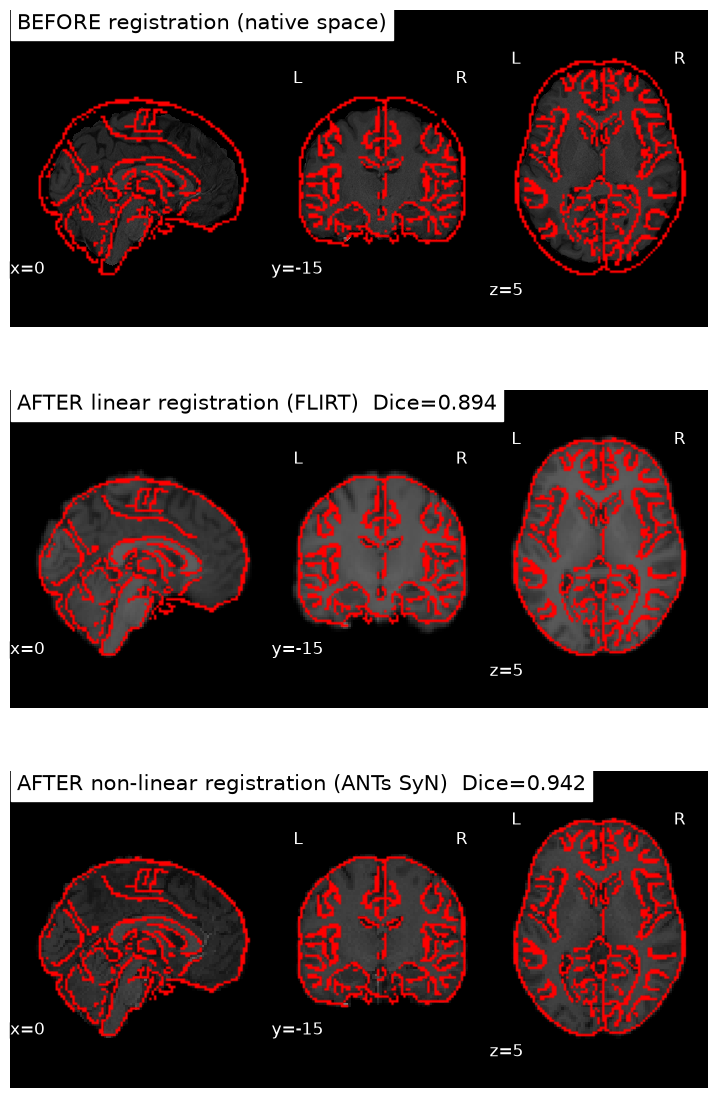

In [8]:
# Plotting pre- and post-registration results, same slices in every panel
CUT_MNI = (0, -15, 5)
fig, axs = plt.subplots(3, 1, figsize=(9, 14))

d = plotting.plot_anat(brain, axes=axs[0], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title="BEFORE registration (native space)")
d.add_edges(mni_brain, color="r") # MNI edges on top

corr, dice = reg_scores["FLIRT"]
d = plotting.plot_anat(brain_flirt, axes=axs[1], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER linear registration (FLIRT)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")

corr, dice = reg_scores["SyN"]
d = plotting.plot_anat(brain_syn, axes=axs[2], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER non-linear registration (ANTs SyN)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")

fig.savefig(op.join(fig_dir, "3_registration_MNI.png"), dpi=FIG_DPI)
plt.show()

# Part 1-2. Functional preprocessing

Order of the steps: the non-stationary volumes are removed before motion correction, because their higher contrast would bias the MCFLIRT reference (the mean volume). Motion correction comes before smoothing, otherwise we would smooth volumes that are not yet aligned.

## 2a. Motion correction (FSL MCFLIRT)

**Purpose.** Make sure that head motion and scanner effects do not drive the GLM.

1. **Looking at the data.** The header confirms the HCP *MNINonLinear* format: 2 mm voxels on the MNI grid, TR = 0.72 s. The last math block goes past the end of the scan and is truncated in the GLM. The global signal (mean of the brain voxels, `fslstats -t -M`) is plotted in figure 4a.
2. **Field stabilization.** Figure 4a shows a short transient: the first volume is brighter and the signal is back to baseline within a few volumes (HCP already discards dummy scans). We remove the first 3 volumes with `fslroi` (10 as in the lab would cut into the first story block), and shift every onset by 3 x TR (`task_onsets_used.csv`).
3. **Motion correction.** MCFLIRT realigns each volume to the mean volume with a rigid-body transform (`-dof 6`: 3 translations, 3 rotations). The estimated motion stays far below a voxel (figure 4b).

In [9]:
func_dir = op.join(data_dir, "fMRI", "tfMRI_LANGUAGE_LR")
func_path = op.join(func_dir, "tfMRI_LANGUAGE_LR.nii.gz")              # original fMRI run (4D)
events_path = op.join(func_dir, "tfMRI_LANGUAGE_LR_task_onsets.csv")   # task timing
mni_brain_2mm = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain.nii.gz")  # template at the fMRI resolution

assert op.exists(func_path), f"fMRI run not found: {func_path}"
assert op.exists(events_path), f"Onsets file not found: {events_path}"
assert shutil.which("mcflirt"), "FSL mcflirt not found in the PATH"


func_img = nib.load(func_path)
n_vols_raw = func_img.shape[3]
voxel_size = func_img.header.get_zooms()[:3]
TR = float(func_img.header.get_zooms()[3])                             # repetition time (s)
print(f"{n_vols_raw} volumes, voxel size {voxel_size} mm, TR = {TR} s, "
      f"on the MNI 2 mm grid: {np.allclose(func_img.affine, nib.load(mni_brain_2mm).affine)}")

events_raw = pd.read_csv(events_path)
last_event_end = (events_raw["onset"] + events_raw["duration"]).max()
print(f"Scan duration: {n_vols_raw * TR:.1f} s   last event ends at: {last_event_end:.1f} s")
if last_event_end > n_vols_raw * TR:
    print("-> the last events go past the end of the scan, they will be truncated in the GLM")

# Global signal: mean of the non-zero (brain) voxels of each volume (-t = one value per volume)
out = subprocess.run(["fslstats", "-t", func_path, "-M"], capture_output=True, text=True, check=True).stdout
global_raw = np.array(out.split(), dtype=float)
baseline = np.median(global_raw[10:])                                   # reference level, after the transient
print("First 10 volumes, % of baseline:", np.round(100 * (global_raw[:10] / baseline - 1), 2))

# Non-stationary volumes: chosen by looking at figure 4a (see the markdown, decided as a group)
N_DISCARD = 3

events = events_raw.copy()
if N_DISCARD > 0:
    func_input = op.join(out_func_dir, "func_trimmed.nii.gz")
    # fslroi: keep volumes N_DISCARD ... end (first volume is 0, not 1!)
    subprocess.run(["fslroi", func_path, func_input, str(N_DISCARD), str(n_vols_raw - N_DISCARD)], check=True)
    events["onset"] -= N_DISCARD * TR                                   # new time origin
    starts_before = events["onset"] < 0                                 # clip what starts before it
    events.loc[starts_before, "duration"] += events.loc[starts_before, "onset"]
    events.loc[starts_before, "onset"] = 0.0
    events = events[events["duration"] > 0].reset_index(drop=True)
else:
    func_input = func_path

n_vols = nib.load(func_input).shape[3]
events.to_csv(op.join(out_func_dir, "task_onsets_used.csv"), index=False)  # onsets to use in the GLM
print(f"Removed {N_DISCARD} volumes ({N_DISCARD * TR:.1f} s), kept {n_vols} volumes")

316 volumes, voxel size (np.float32(2.0), np.float32(2.0), np.float32(2.0)) mm, TR = 0.7200000286102295 s, on the MNI 2 mm grid: True
Scan duration: 227.5 s   last event ends at: 232.2 s
-> the last events go past the end of the scan, they will be truncated in the GLM


First 10 volumes, % of baseline: [0.98 0.49 0.24 0.07 0.13 0.19 0.16 0.23 0.33 0.36]


Removed 3 volumes (2.2 s), kept 313 volumes


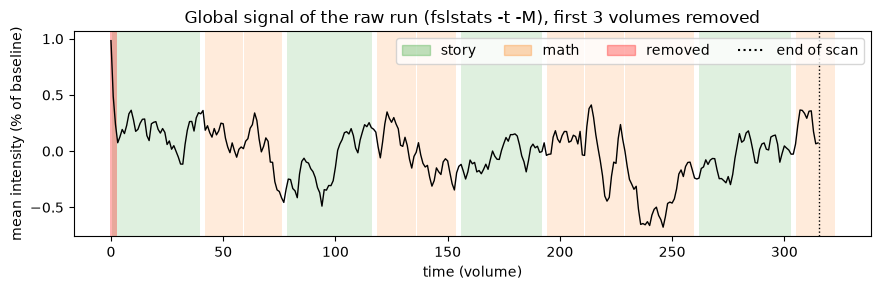

In [10]:
# Plotting the global signal of the raw run, with the task blocks and the removed volumes
block_colors = {"story": "tab:green", "math": "tab:orange"}
blocks_raw = events_raw[events_raw["trial_type"].isin(["story", "math"])]

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(n_vols_raw), 100 * (global_raw / baseline - 1), color="k", lw=1)
for _, ev in blocks_raw.iterrows():                                     # task blocks, converted from s to volumes
    ax.axvspan(ev["onset"] / TR, (ev["onset"] + ev["duration"]) / TR,
               color=block_colors[ev["trial_type"]], alpha=0.15, lw=0)
if N_DISCARD > 0:
    ax.axvspan(-0.5, N_DISCARD - 0.5, color="r", alpha=0.3, lw=0)       # removed volumes
ax.axvline(n_vols_raw - 0.5, color="k", ls=":", lw=1)                   # end of the scan
ax.set(xlabel="time (volume)", ylabel="mean intensity (% of baseline)",
       title=f"Global signal of the raw run (fslstats -t -M), first {N_DISCARD} volumes removed")
ax.legend(handles=[Patch(color="tab:green", alpha=0.3, label="story"),
                   Patch(color="tab:orange", alpha=0.3, label="math"),
                   Patch(color="r", alpha=0.3, label="removed"),
                   plt.Line2D([], [], color="k", ls=":", label="end of scan")], loc="upper right", ncol=4)

fig.tight_layout()
fig.savefig(op.join(fig_dir, "4a_global_signal.png"), dpi=FIG_DPI)
plt.show()

In [11]:
mc_prefix = op.join(out_func_dir, "func_mc")
func_mc = mc_prefix + ".nii.gz"           # motion-corrected run
par_file = mc_prefix + ".par"             # 6 motion parameters per volume

# 3. MCFLIRT: rigid-body (6 DOF) realignment to the mean volume (takes a few minutes)
subprocess.run(["mcflirt", "-in", func_input, "-out", mc_prefix, "-dof", "6",
                "-meanvol", "-plots", "-rmsabs", "-rmsrel", "-spline_final"], check=True)
motion = np.loadtxt(par_file)             # columns: rx ry rz (rad), tx ty tz (mm)
assert motion.shape[0] == n_vols

# 4. Framewise displacement (Power et al., 2012)
HEAD_RADIUS = 50.0                        # mm, converts rotations (rad) into displacements (mm)
FD_THRESH = 0.5                           # mm, absolute threshold for the irregular volumes
delta = np.abs(np.diff(motion, axis=0))
fd = np.concatenate([[0.0], delta[:, 3:].sum(axis=1) + HEAD_RADIUS * delta[:, :3].sum(axis=1)])  # FD = 0 at the first volume
np.savetxt(op.join(out_func_dir, "fd.txt"), fd, fmt="%.5f")

q1, q3 = np.quantile(fd, [0.25, 0.75])
fd_boxplot = q3 + 1.5 * (q3 - q1)         # threshold of the lab, for comparison
outliers = np.where(fd > FD_THRESH)[0]
print(f"FD: mean = {fd.mean():.3f} mm, median = {np.median(fd):.3f} mm, max = {fd.max():.3f} mm")
print(f"Volumes with FD > {FD_THRESH} mm: {len(outliers)} / {n_vols}  {outliers.tolist()}")
print(f"(boxplot threshold Q3 + 1.5 IQR = {fd_boxplot:.3f} mm would flag {(fd > fd_boxplot).sum()} volumes)")

# 5. Irregular volumes: one spike regressor per flagged volume, saved with the 6 motion parameters for the GLM
spikes = np.zeros((n_vols, len(outliers)))
spikes[outliers, np.arange(len(outliers))] = 1
confounds = np.column_stack([motion, spikes])
np.savetxt(op.join(out_func_dir, "motion_confounds.txt"), confounds, fmt="%.6f")
print(f"Confound matrix: {confounds.shape}  (6 motion parameters + {len(outliers)} spike regressors)")

FD: mean = 0.094 mm, median = 0.076 mm, max = 0.391 mm
Volumes with FD > 0.5 mm: 0 / 313  []
(boxplot threshold Q3 + 1.5 IQR = 0.279 mm would flag 4 volumes)
Confound matrix: (313, 6)  (6 motion parameters + 0 spike regressors)


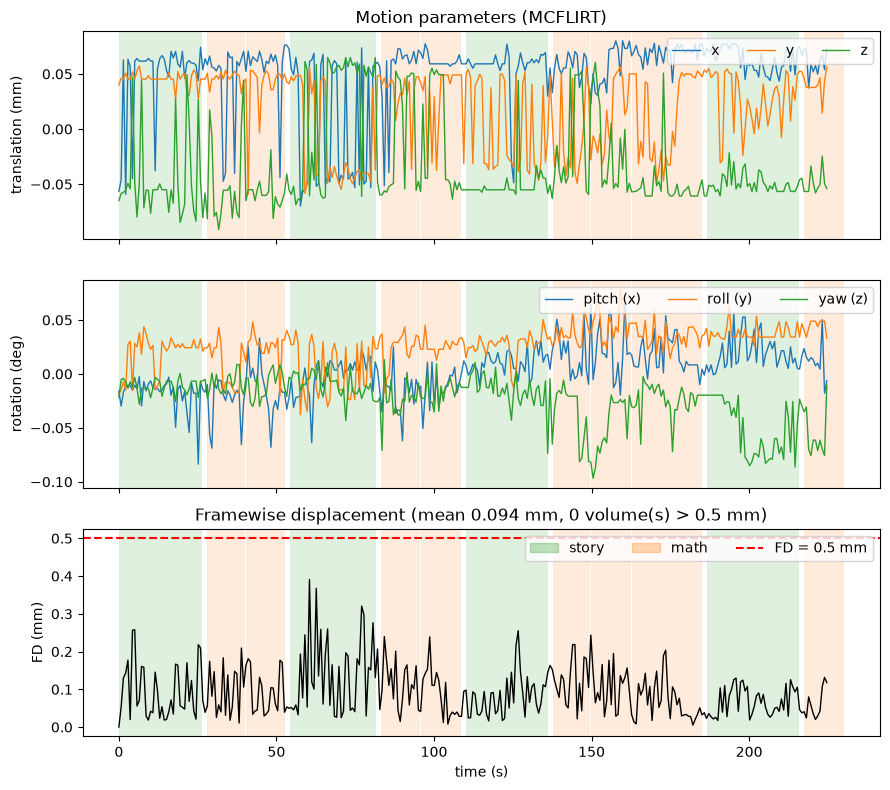

In [12]:
# Plotting the motion parameters and the FD, with the task blocks in the background
t = np.arange(n_vols) * TR
blocks = events[events["trial_type"].isin(["story", "math"])]           # onsets after the possible shift

fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
axs[0].plot(t, motion[:, 3:], lw=1)
axs[0].set(ylabel="translation (mm)", title="Motion parameters (MCFLIRT)")
axs[0].legend(["x", "y", "z"], loc="upper right", ncol=3)
axs[1].plot(t, np.degrees(motion[:, :3]), lw=1)
axs[1].set(ylabel="rotation (deg)")
axs[1].legend(["pitch (x)", "roll (y)", "yaw (z)"], loc="upper right", ncol=3)
axs[2].plot(t, fd, color="k", lw=1)
axs[2].axhline(FD_THRESH, color="r", ls="--")
axs[2].scatter(t[outliers], fd[outliers], color="r", zorder=3)
axs[2].set(ylabel="FD (mm)", xlabel="time (s)",
           title=f"Framewise displacement (mean {fd.mean():.3f} mm, {len(outliers)} volume(s) > {FD_THRESH} mm)")

for ax in axs:                                                          # shade the story/math blocks
    for _, ev in blocks.iterrows():
        ax.axvspan(ev["onset"], ev["onset"] + ev["duration"], color=block_colors[ev["trial_type"]], alpha=0.15, lw=0)
axs[2].legend(handles=[Patch(color="tab:green", alpha=0.3, label="story"),
                       Patch(color="tab:orange", alpha=0.3, label="math"),
                       plt.Line2D([], [], color="r", ls="--", label=f"FD = {FD_THRESH} mm")],
              loc="upper right", ncol=3)

fig.tight_layout()
fig.savefig(op.join(fig_dir, "4b_motion_FD.png"), dpi=FIG_DPI)
plt.show()

## 2b. Gaussian smoothing (FSL)

**Purpose.** Averaging neighbouring voxels with a 3D Gaussian reduces the noise, which is mostly independent from voxel to voxel, while keeping the activations, which extend over several voxels. It also brings the data closer to the assumptions of the voxel-wise statistics (Gaussian random fields). The price is spatial specificity: small activations get diluted.

**Parameters.** FWHM = 6 mm, 3 times the 2 mm voxel size (8 mm is usually kept for group studies). FSL takes a sigma: σ = FWHM / (2√(2 ln 2)) ≈ 2.55 mm. The smoothing is done inside a brain mask (BET on the mean fMRI), and divided by the smoothed mask so that the edges of the brain are not darkened by the zeros outside it.

In [13]:
# Functional brain mask: BET on the temporal mean of the motion-corrected run
mean_func = op.join(out_func_dir, "func_mc_mean.nii.gz")          # temporal mean (3D)
func_brain_prefix = op.join(out_func_dir, "func_mean_brain")
func_mask = func_brain_prefix + "_mask.nii.gz"                     # functional brain mask
func_mc_brain = op.join(out_func_dir, "func_mc_brain.nii.gz")      # masked motion-corrected run

subprocess.run(["fslmaths", func_mc, "-Tmean", mean_func], check=True)
subprocess.run(["bet", mean_func, func_brain_prefix, "-f", "0.3", "-m"], check=True)
subprocess.run(["fslmaths", func_mc, "-mas", func_mask, func_mc_brain], check=True)
print(f"Functional mask volume: {volume_ml(func_mask):.0f} mL   (T1 BET mask: {volume_ml(mask):.0f} mL)")

# Gaussian smoothing inside the mask: smooth(data) / smooth(mask), then re-mask
FWHM = 6.0                                                         # mm
sigma = FWHM / (2 * np.sqrt(2 * np.log(2)))                        # FSL uses sigma, not FWHM
func_smooth = op.join(out_func_dir, f"func_mc_brain_smooth{FWHM:.0f}mm.nii.gz")
tmp_num = op.join(out_func_dir, "tmp_smooth_data.nii.gz")
tmp_den = op.join(out_func_dir, "tmp_smooth_mask.nii.gz")

subprocess.run(["fslmaths", func_mc_brain, "-s", f"{sigma:.4f}", tmp_num], check=True)
subprocess.run(["fslmaths", func_mask, "-s", f"{sigma:.4f}", tmp_den], check=True)
subprocess.run(["fslmaths", tmp_num, "-div", tmp_den, "-mas", func_mask, func_smooth, "-odt", "float"], check=True)
os.remove(tmp_num); os.remove(tmp_den)
print(f"FWHM = {FWHM} mm  ->  sigma = {sigma:.3f} mm")

def median_tsnr(img_4d, mask_path):
    """Median temporal SNR (mean / std over time) in the mask, computed with fslmaths."""
    m, s, r = (op.join(out_func_dir, f"tmp_{k}.nii.gz") for k in ("mean", "std", "tsnr"))
    subprocess.run(["fslmaths", img_4d, "-Tmean", m], check=True)
    subprocess.run(["fslmaths", img_4d, "-Tstd", s], check=True)
    subprocess.run(["fslmaths", m, "-div", s, "-mas", mask_path, r], check=True)
    vals = nib.load(r).get_fdata()[nib.load(mask_path).get_fdata() > 0]
    for f in (m, s, r): os.remove(f)
    return np.median(vals)

tsnr_before, tsnr_after = median_tsnr(func_mc_brain, func_mask), median_tsnr(func_smooth, func_mask)
print(f"Median tSNR  before smoothing: {tsnr_before:.1f}   after: {tsnr_after:.1f}")

Functional mask volume: 1874 mL   (T1 BET mask: 1379 mL)


FWHM = 6.0 mm  ->  sigma = 2.548 mm


Median tSNR  before smoothing: 32.6   after: 127.4


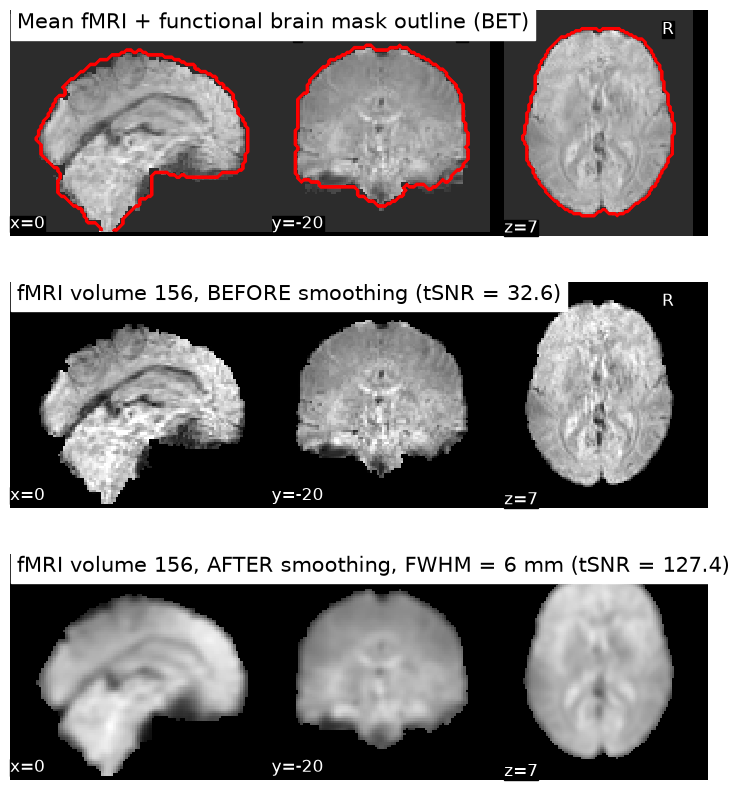

In [14]:
# Plotting the functional mask, then one volume before and after smoothing (same slices, same intensity scale)
VOL = n_vols // 2                                    # volume of our choice: the middle of the run
vol_before = op.join(out_func_dir, f"vol{VOL}_before_smoothing.nii.gz")
vol_after = op.join(out_func_dir, f"vol{VOL}_after_smoothing.nii.gz")
subprocess.run(["fslroi", func_mc_brain, vol_before, str(VOL), "1"], check=True)   # extract 1 volume
subprocess.run(["fslroi", func_smooth, vol_after, str(VOL), "1"], check=True)

data_before = nib.load(vol_before).get_fdata()
vmax = np.percentile(data_before[data_before > 0], 99)  # common scale for both volumes

CUT_FUNC = (0, -20, 7)
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

d = plotting.plot_epi(mean_func, axes=axs[0], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False, cmap="gray",
                      title="Mean fMRI + functional brain mask outline (BET)")
d.add_contours(func_mask, colors="r", linewidths=1)

plotting.plot_epi(vol_before, axes=axs[1], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False,
                  cmap="gray", vmin=0, vmax=vmax, title=f"fMRI volume {VOL}, BEFORE smoothing (tSNR = {tsnr_before:.1f})")

plotting.plot_epi(vol_after, axes=axs[2], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False,
                  cmap="gray", vmin=0, vmax=vmax,
                  title=f"fMRI volume {VOL}, AFTER smoothing, FWHM = {FWHM:.0f} mm (tSNR = {tsnr_after:.1f})")

fig.savefig(op.join(fig_dir, "5_smoothing.png"), dpi=FIG_DPI)
plt.show()

## 2c. Validation of the anatomical-functional alignment

**Which step can be avoided?** The coregistration of the fMRI to the T1 and its normalisation to MNI. The HCP fMRI is already non-linearly normalised to the MNI 2 mm grid, and the remaining misalignment is below one voxel. Registering it again would add an interpolation that blurs the data for at most half a voxel of gain.

Dice (functional vs T1 brain mask): 0.951
Residual misalignment found by FLIRT (RMS displacement): 0.89 mm  (voxel size 2 mm)


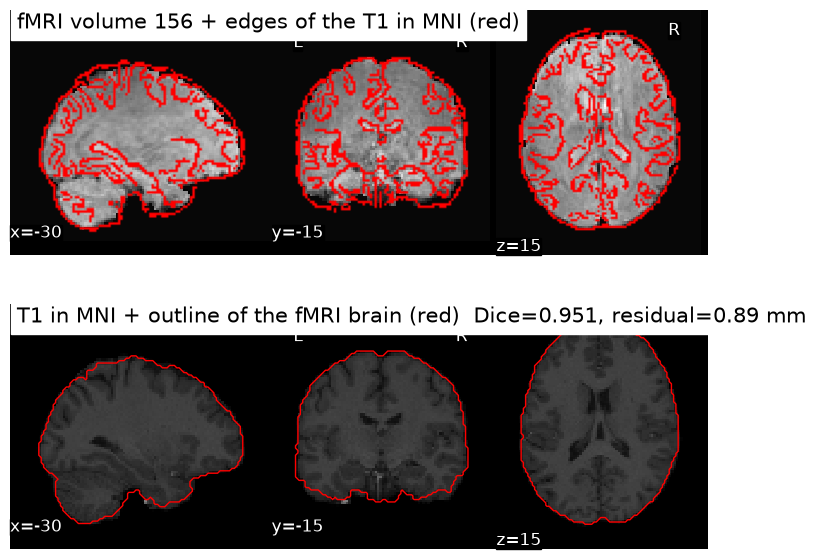

In [15]:
# Dice between the functional mask (resampled to 1 mm) and the T1 brain mask in MNI (outer boundary only)
func_mask_1mm = image.resample_to_img(func_mask, brain_syn, interpolation="nearest").get_fdata() > 0
t1_mask_mni = nib.load(brain_syn).get_fdata() > 0
dice_func_t1 = 2 * (func_mask_1mm & t1_mask_mni).sum() / (func_mask_1mm.sum() + t1_mask_mni.sum())

# Residual misalignment: rigid FLIRT of the mean fMRI onto the T1 in MNI, starting from the current position.
# If the data are aligned, FLIRT finds (almost) the identity: the RMS displacement it would apply is ~0 mm.
resid_mat = op.join(out_func_dir, "func_to_T1MNI_residual.mat")
ident_mat = op.join(out_func_dir, "identity.mat")
np.savetxt(ident_mat, np.eye(4), fmt="%.1f")
subprocess.run(["flirt", "-in", mean_func, "-ref", brain_syn, "-omat", resid_mat,
                "-dof", "6", "-cost", "normmi", "-nosearch"], check=True)   # normmi: different contrasts (EPI vs T1)
rms_resid = float(subprocess.run(["rmsdiff", ident_mat, resid_mat, brain_syn],
                                 capture_output=True, text=True, check=True).stdout.split()[0])
print(f"Dice (functional vs T1 brain mask): {dice_func_t1:.3f}")
print(f"Residual misalignment found by FLIRT (RMS displacement): {rms_resid:.2f} mm  (voxel size {voxel_size[0]:.0f} mm)")

# Plotting: T1 edges over the fMRI, and the fMRI brain outline over the T1
CUT_ALIGN = (-30, -15, 15)                           # lateral slices through the ventricles and the insula
fig, axs = plt.subplots(2, 1, figsize=(9, 7))

d = plotting.plot_epi(vol_before, axes=axs[0], cut_coords=CUT_ALIGN, draw_cross=False, colorbar=False, cmap="gray",
                      title=f"fMRI volume {VOL} + edges of the T1 in MNI (red)")
d.add_edges(brain_syn, color="r")

d = plotting.plot_anat(brain_syn, axes=axs[1], cut_coords=CUT_ALIGN, draw_cross=False, colorbar=False,
                       title=f"T1 in MNI + outline of the fMRI brain (red)  Dice={dice_func_t1:.3f}, "
                             f"residual={rms_resid:.2f} mm")
d.add_contours(func_mask, levels=[0.5], colors="r", linewidths=1)

fig.savefig(op.join(fig_dir, "6_func_anat_alignment.png"), dpi=FIG_DPI)
plt.show()

# Part 1-3. GLM

Inputs from part 1-2: the preprocessed run (`func_mc_brain_smooth6mm.nii.gz`, 313 volumes), the shifted onsets and the motion confounds.

In [16]:
func_img_path = func_smooth                         # output of part 1-2
n_scans, t_r = n_vols, TR
frame_times = np.arange(n_scans) * t_r              # same convention as FirstLevelModel (slice_time_ref=0)
print(f"{n_scans} volumes, TR = {t_r} s, run duration = {n_scans * t_r:.1f} s")
print(events.groupby("trial_type")["duration"].agg(["count", "mean", "sum"]).round(2))

313 volumes, TR = 0.7200000286102295 s, run duration = 225.4 s
                count   mean     sum
trial_type                          
cue                 7   0.77    5.38
math                9  12.08  108.72
present_math        9   5.46   49.14
present_story       4  19.55   78.19
question_math       9   3.45   31.09
question_story      4   1.16    4.64
response_math       9   2.96   26.66
response_story      4   2.96   11.84
story               4  27.22  108.87


## 3a. Design matrix

The event file has two levels of description, which overlap in time (a block is almost the sum of its sub-events), so they go in two models:
1. **Block design (main model)**: `story`, `math`. It answers the question of the project (story vs math) with the most power, and is the design of Binder et al. (2011).
2. **Event design (detailed model)**: the 7 sub-events `present_*`, `question_*`, `response_*` and the auditory `cue`.

Common settings:
- **HRF**: canonical SPM (double gamma), as in lab 5. The blocks are long (12-30 s), so a small mismatch in the HRF shape changes the regressors little, and no temporal derivative is added.
- **Drifts**: cosine basis with a 0.01 Hz high-pass cut-off (4 regressors). The task alternates with a period of ~55-60 s, above the cut-off.
- **Motion**: the 6 MCFLIRT parameters of part 1-2 (no spike regressor: no volume has FD > 0.5 mm).
- **Constant**.

In [17]:
HRF_MODEL = "spm"
DRIFT_MODEL = "cosine"
HIGH_PASS = 0.01                                    # Hz

BLOCK_CONDITIONS = ["story", "math"]
EVENT_CONDITIONS = ["present_story", "question_story", "response_story",
                    "present_math", "question_math", "response_math", "cue"]

# Motion confounds (part 1-2)
assert confounds.shape[0] == n_scans, "confounds and fMRI run must have the same number of volumes"
motion_names = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]
motion_names += [f"spike_{k}" for k in range(confounds.shape[1] - 6)]


def build_design(conditions):
    """First-level design matrix for a subset of the event types."""
    ev = events[events["trial_type"].isin(conditions)]
    return make_first_level_design_matrix(frame_times, ev, hrf_model=HRF_MODEL,
                                          drift_model=DRIFT_MODEL, high_pass=HIGH_PASS,
                                          add_regs=confounds, add_reg_names=motion_names)


dm_block = build_design(BLOCK_CONDITIONS)
dm_event = build_design(EVENT_CONDITIONS)
drift_cols = [c for c in dm_block.columns if c.startswith("drift")]
print("Block design:", dm_block.shape, list(dm_block.columns))
print("Event design:", dm_event.shape, list(dm_event.columns))

# Saved with the other outputs
dm_block.to_csv(op.join(glm_dir, "design_matrix_block.csv"))
dm_event.to_csv(op.join(glm_dir, "design_matrix_event.csv"))

Block design: (313, 13) ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']
Event design: (313, 18) ['cue', 'present_math', 'present_story', 'question_math', 'question_story', 'response_math', 'response_story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


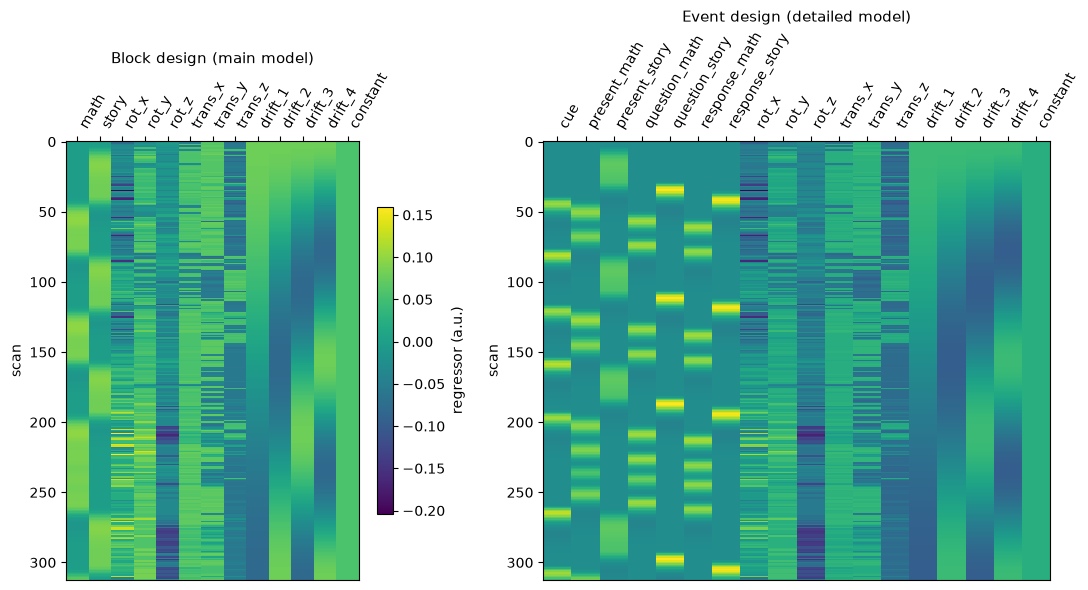

In [18]:
# Figure: both design matrices side by side
fig, axs = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [dm_block.shape[1], dm_event.shape[1]]})
plot_design_matrix(dm_block, axes=axs[0])
axs[0].set_title("Block design (main model)", fontsize=11)
fig.colorbar(axs[0].images[0], ax=axs[0], shrink=0.7, label="regressor (a.u.)")
plot_design_matrix(dm_event, axes=axs[1])
axs[1].set_title("Event design (detailed model)", fontsize=11)
for ax in axs:
    ax.set_ylabel("scan")
fig.tight_layout()
fig.savefig(op.join(fig_dir, "7a_design_matrix.png"), dpi=FIG_DPI)
plt.show()

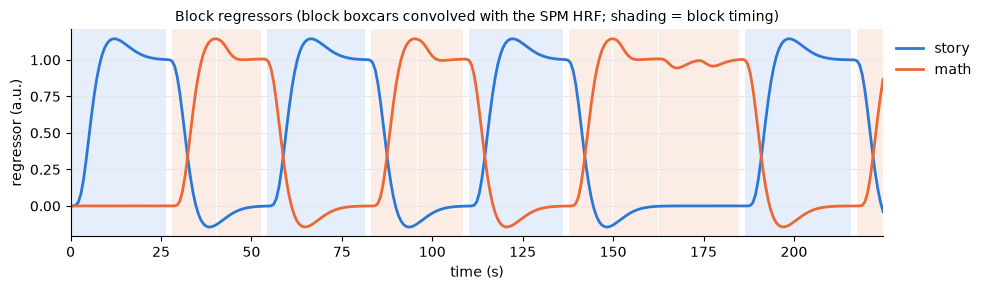

In [19]:
# Figure: task regressors of the block design over time, with the blocks shaded
fig, ax = plt.subplots(figsize=(10, 3))
for _, ev in events[events["trial_type"].isin(BLOCK_CONDITIONS)].iterrows():
    color = STORY_COLOR if ev["trial_type"] == "story" else MATH_COLOR
    ax.axvspan(ev["onset"], ev["onset"] + ev["duration"], color=color, alpha=0.12, lw=0)
ax.plot(frame_times, dm_block["story"], color=STORY_COLOR, lw=2, label="story")
ax.plot(frame_times, dm_block["math"], color=MATH_COLOR, lw=2, label="math")
ax.set_xlabel("time (s)")
ax.set_ylabel("regressor (a.u.)")
ax.set_xlim(0, frame_times[-1])
ax.set_title("Block regressors (block boxcars convolved with the SPM HRF; shading = block timing)", fontsize=10)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9")
fig.tight_layout()
fig.savefig(op.join(fig_dir, "7a_block_regressors.png"), dpi=FIG_DPI)
plt.show()

## 3b. Correlation between the regressors

Pearson correlation between the columns of each design matrix (the constant is left out). The variance inflation factor (VIF = 1 / (1 - R²) of each regressor regressed on all the others) summarises how much each beta's variance is inflated by collinearity.

In [20]:
def vif(dm, columns):
    """Variance inflation factor of each column, regressed on all the other columns of dm."""
    out = {}
    for col in columns:
        y = dm[col].to_numpy()
        X = dm.drop(columns=col).to_numpy()
        resid = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
        r2 = 1 - resid.var() / y.var()
        out[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out)


corr_block = dm_block.drop(columns="constant").corr()
corr_event = dm_event.drop(columns="constant").corr()
print("Block design correlations (task regressors):\n", corr_block.loc[BLOCK_CONDITIONS, BLOCK_CONDITIONS].round(3))
print("\nVIF block design:\n", vif(dm_block, BLOCK_CONDITIONS).round(2))
print("\nVIF event design:\n", vif(dm_event, EVENT_CONDITIONS).round(2))

# Largest absolute correlations between task regressors of the event design
task_corr = corr_event.loc[EVENT_CONDITIONS, EVENT_CONDITIONS]
pairs = (task_corr.where(np.triu(np.ones(task_corr.shape, bool), k=1)).stack()
         .sort_values(key=np.abs, ascending=False))
print("\nEvent design, strongest task correlations:\n", pairs.head(6).round(3))

# Task-correlated motion: a motion regressor that follows the task would remove task signal
print("\nCorrelation of the motion parameters with the block regressors:\n",
      corr_block.loc[motion_names, BLOCK_CONDITIONS].round(3))
print("\nCorrelation of the motion parameters with the drifts (max |r|):\n",
      corr_block.loc[motion_names, drift_cols].abs().max(axis=1).round(3))

Block design correlations (task regressors):
        story   math
story  1.000 -0.943
math  -0.943  1.000

VIF block design:
 story    10.50
math     12.14
dtype: float64

VIF event design:
 present_story     12.63
question_story     2.96
response_story     4.63
present_math       6.70
question_math      4.06
response_math      3.89
cue                2.02
dtype: float64

Event design, strongest task correlations:
 present_story   present_math     -0.562
response_story  cue               0.504
present_story   question_math    -0.486
question_math   response_math     0.471
present_story   response_math    -0.400
                response_story   -0.347
dtype: float64

Correlation of the motion parameters with the block regressors:
          story   math
rot_x    0.114 -0.074
rot_y   -0.143  0.204
rot_z   -0.074  0.034
trans_x -0.183  0.254
trans_y -0.170  0.133
trans_z  0.014  0.007

Correlation of the motion parameters with the drifts (max |r|):
 rot_x      0.624
rot_y      0.527
rot_z 

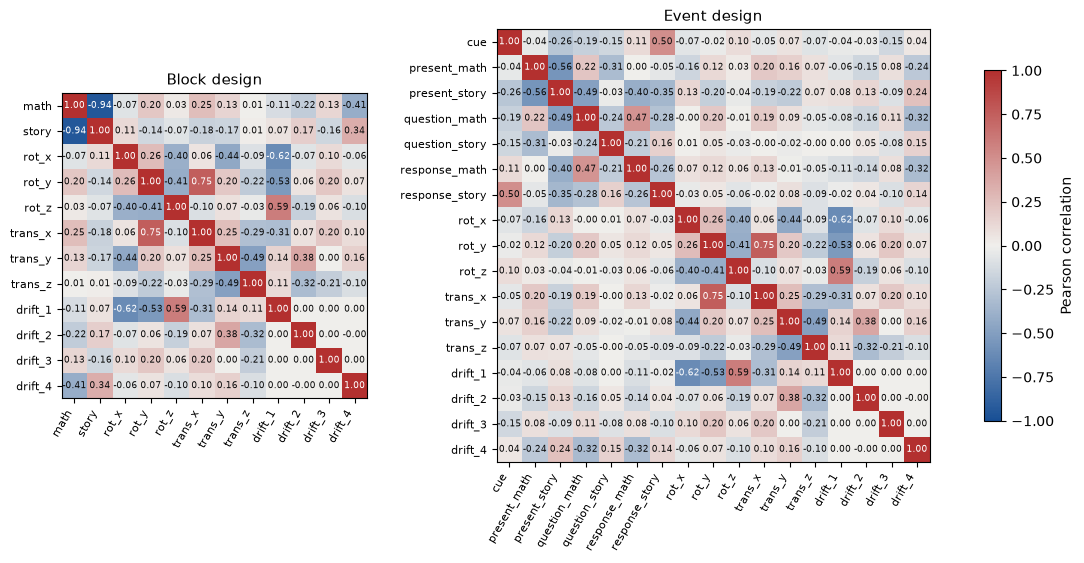

In [21]:
# Figure: correlation matrices (diverging blue - gray - red, symmetric -1..1)
def plot_corr(corr, ax, title):
    n = len(corr)
    im = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(n), corr.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(n), corr.index, fontsize=8)
    for i in range(n):
        for j in range(n):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(v) > 0.6 else "#0b0b0b")
    ax.set_title(title, fontsize=11)
    return im


fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [len(corr_block), len(corr_event)],
                                                                "wspace": 0.35})
plot_corr(corr_block, axs[0], "Block design")
im = plot_corr(corr_event, axs[1], "Event design")
fig.colorbar(im, ax=axs, shrink=0.7, label="Pearson correlation")
fig.savefig(op.join(fig_dir, "7b_regressor_correlation.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3b for Block design

**`story` and `math` are strongly anti-correlated (r = -0.94, VIF 10.5 and 12.1).** The blocks alternate with no rest and cover 94.5% of the run, so `story + math` is almost equal to the constant. The individual betas are therefore poorly estimated (3c), but the difference **story - math**, which swings from +1 to -1 at every alternation, is well estimated (3d). This is the logic of the task: math is an active control matched in duration, auditory input and button press (Binder et al., 2011).

**Drifts.** `drift_4` (period ~113 s) correlates moderately with the task (r = 0.34 with story, -0.41 with math), because of the four consecutive math blocks between 138 and 185 s. A lower cut-off (e.g. 1/128 Hz) would reduce it, at the cost of less drift removal.

**Motion.** The motion parameters are weakly correlated with the task (|r| ≤ 0.25): no task-correlated motion, so adding them removes little task signal. They correlate more with the drifts (|r| up to 0.62), and `rot_y` with `trans_x` (0.75), because MCFLIRT rotates around the centre of the volume, not of the brain.

## 3c. GLM and statistical maps of the task regressors

First-level GLM (one subject, one run), fitted voxel by voxel with the design matrices of 3a. Settings as in lab 5:
- **mask**: functional brain mask of part 1-2; no extra smoothing (already 6 mm);
- **thresholding**: FDR q < 0.05, two-sided, clusters of at least 10 voxels.

In [22]:
anat_mni = brain_syn                                # T1 in MNI (part 1-1), background of the maps

FDR_ALPHA = 0.05
CLUSTER_SIZE = 10                                   # voxels
Z_CUTS = [-24, -12, -4, 4, 14, 26, 40, 52]          # axial slices (MNI z, mm)
Z_VMAX = 10                                         # common colour scale for all the maps


def fit_glm(design):
    glm = FirstLevelModel(t_r=t_r, mask_img=func_mask, smoothing_fwhm=None, noise_model="ar1",
                          signal_scaling=0, minimize_memory=True)
    return glm.fit(func_img_path, design_matrices=design)


def contrast_vector(design, weights):
    """Contrast vector over all the columns of the design matrix, from a {column: weight} dict."""
    vec = np.zeros(design.shape[1])
    for col, w in weights.items():
        vec[design.columns.get_loc(col)] = w
    return vec


def threshold(z_map, control="fdr", alpha=FDR_ALPHA):
    """FDR q < 0.05 (two-sided) + cluster extent, as in lab 5. Returns the thresholded map and the z threshold."""
    return threshold_stats_img(z_map, mask_img=func_mask, alpha=alpha, height_control=control,
                               cluster_threshold=CLUSTER_SIZE, two_sided=True)


def plot_map(z_thr, z_thr_value, title, axes, vmax=Z_VMAX):
    display = plotting.plot_stat_map(z_thr, bg_img=anat_mni, display_mode="z", cut_coords=Z_CUTS, axes=axes,
                                     threshold=z_thr_value, vmax=vmax, cmap="RdBu_r", black_bg=False,
                                     annotate=True, draw_cross=False)
    # title above the slices, so that it does not hide the L/R labels
    display.title(title, y=1.12, size=9, color="black", bgcolor="white")
    return display


glm_block = fit_glm(dm_block)
glm_event = fit_glm(dm_event)

/var/folders/b7/1yj9d58j6916jyl63yg2qmvm0000gn/T/ipykernel_72735/4060756914.py:12: UserWarning: If design matrices are supplied, [t_r] will be ignored.
  return glm.fit(func_img_path, design_matrices=design)
/var/folders/b7/1yj9d58j6916jyl63yg2qmvm0000gn/T/ipykernel_72735/4060756914.py:12: RuntimeWarning: [MultiNiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  return glm.fit(func_img_path, design_matrices=design)


In [23]:
# Statistical map of each task regressor (each regressor vs the implicit baseline)
z_maps = {}
for name, glm, design, conditions in [("block", glm_block, dm_block, BLOCK_CONDITIONS),
                                      ("event", glm_event, dm_event, EVENT_CONDITIONS)]:
    for cond in conditions:
        z = glm.compute_contrast(contrast_vector(design, {cond: 1}), output_type="z_score")
        z.to_filename(op.join(glm_dir, f"zmap_{name}_{cond}.nii.gz"))
        z_maps[(name, cond)] = z

summary = []
for (name, cond), z in z_maps.items():
    z_thr, thr = threshold(z)
    data = z_thr.get_fdata()
    summary.append({"model": name, "regressor": cond, "z threshold": round(thr, 2),
                    "voxels z>0": int((data > 0).sum()), "voxels z<0": int((data < 0).sum()),
                    "max z": round(float(z.get_fdata().max()), 1), "min z": round(float(z.get_fdata().min()), 1)})
summary = pd.DataFrame(summary)
summary.to_csv(op.join(glm_dir, "regressor_maps_summary.csv"), index=False)
print(summary.to_string(index=False))

model      regressor  z threshold  voxels z>0  voxels z<0  max z  min z
block          story         4.13           0         145    4.4   -5.4
block           math         3.63          22        1116    4.2   -5.5
event  present_story         4.75           0           0    5.3   -5.1
event question_story         3.19        6071         311    6.3   -5.3
event response_story         3.58        1051         328    6.2   -5.4
event   present_math         2.99        8139        4392    7.1   -6.1
event  question_math         3.88         288          77    5.5   -5.0
event  response_math         3.32         946        2844    5.3   -6.7
event            cue         3.44        2500          60    6.9   -4.6


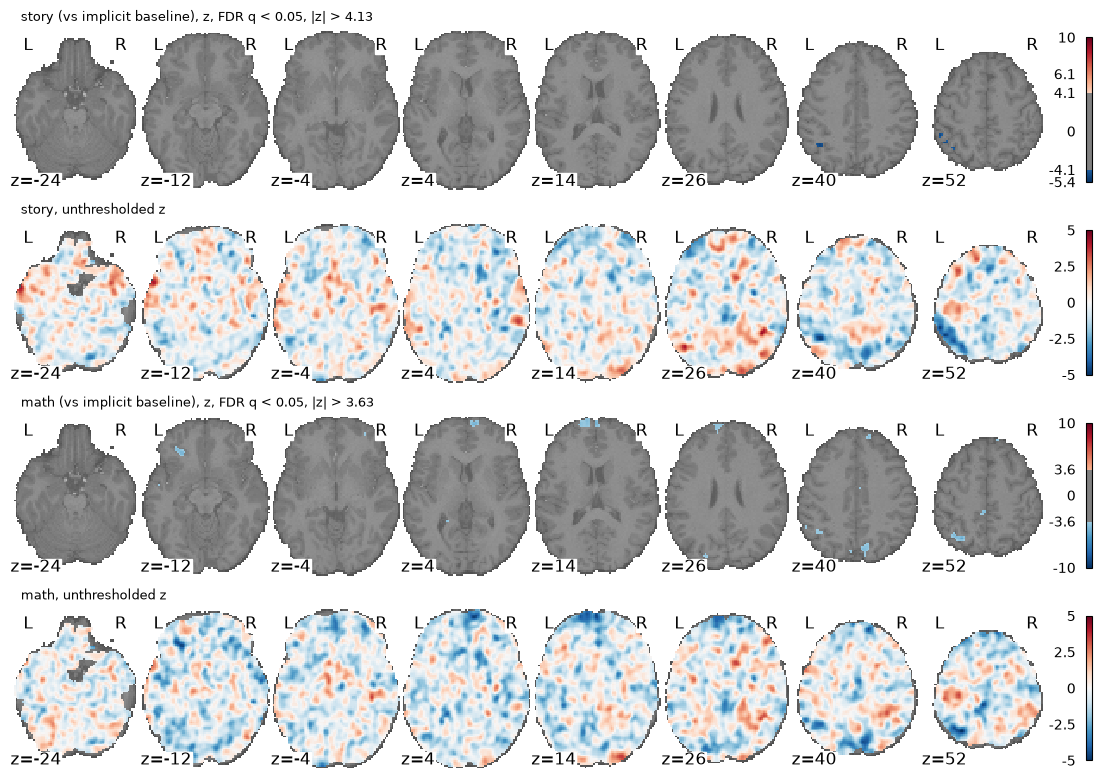

/var/folders/b7/1yj9d58j6916jyl63yg2qmvm0000gn/T/ipykernel_72735/4060756914.py:30: UserWarning: empty mask
  display = plotting.plot_stat_map(z_thr, bg_img=anat_mni, display_mode="z", cut_coords=Z_CUTS, axes=axes,


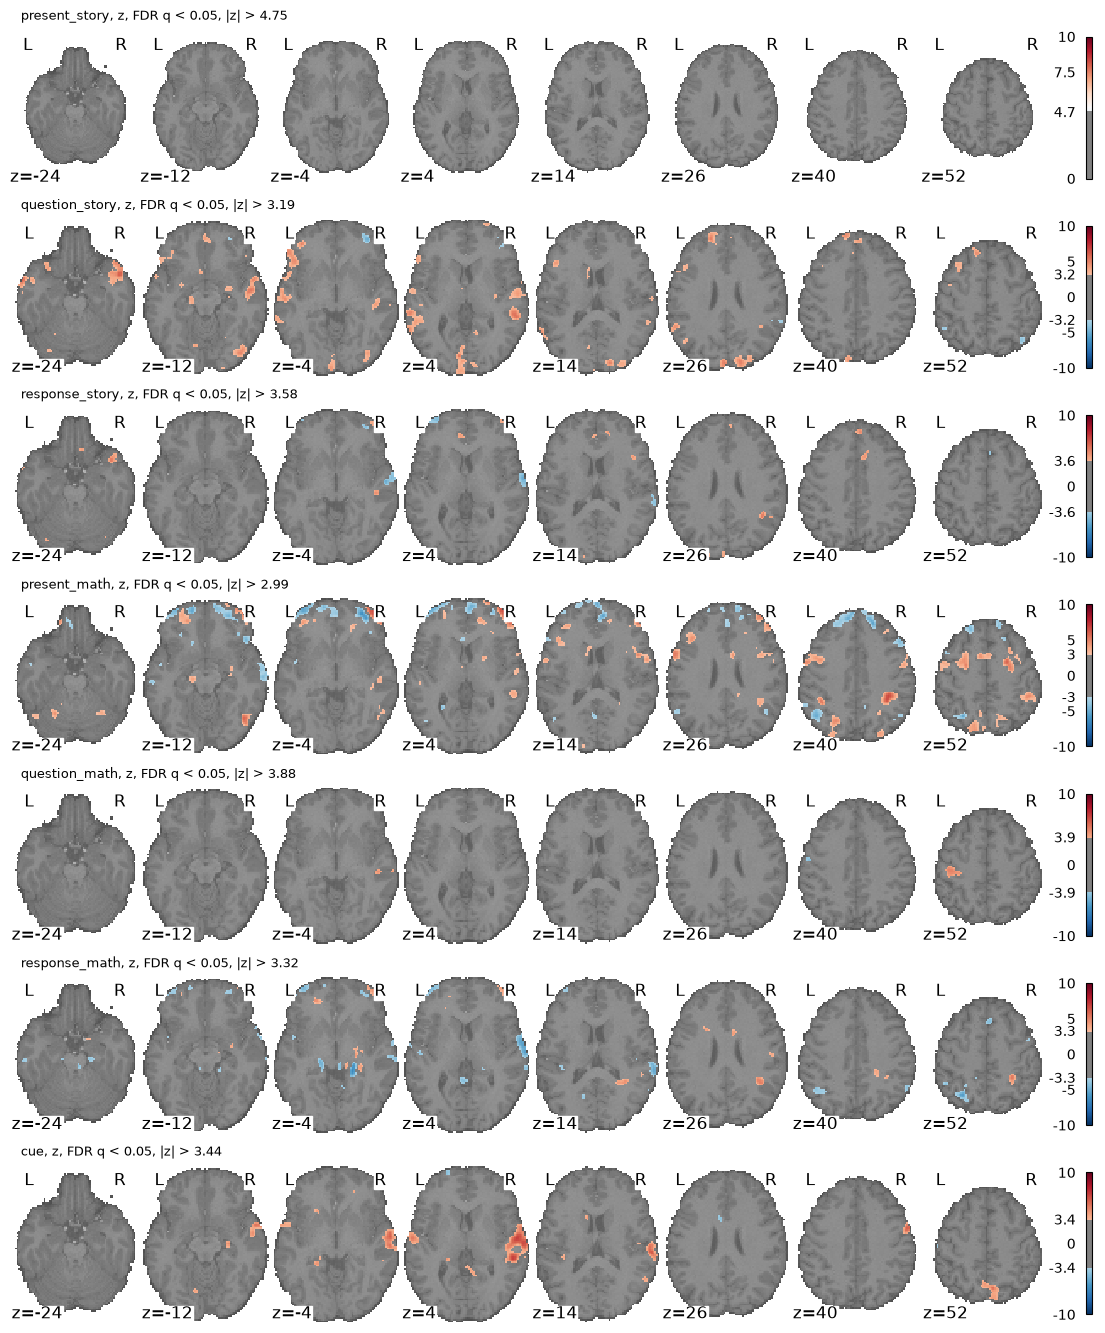

In [24]:
# Figure: block design, two rows per task regressor: thresholded map, then the unthresholded map
# (the thresholded maps are almost empty, see the comments; the raw map shows the spatial pattern behind them)
fig, axs = plt.subplots(2 * len(BLOCK_CONDITIONS), 1, figsize=(14, 2.4 * 2 * len(BLOCK_CONDITIONS)))
for k, cond in enumerate(BLOCK_CONDITIONS):
    z_thr, thr = threshold(z_maps[("block", cond)])
    plot_map(z_thr, thr, f"{cond} (vs implicit baseline), z, FDR q < {FDR_ALPHA}, |z| > {thr:.2f}", axs[2 * k])
    plot_map(z_maps[("block", cond)], 0, f"{cond}, unthresholded z", axs[2 * k + 1], vmax=5)
fig.savefig(op.join(fig_dir, "7c_regressor_maps_block.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

# Figure (appendix): event design, one row per sub-event regressor
fig, axs = plt.subplots(len(EVENT_CONDITIONS), 1, figsize=(14, 2.4 * len(EVENT_CONDITIONS)))
for ax, cond in zip(axs, EVENT_CONDITIONS):
    z_thr, thr = threshold(z_maps[("event", cond)])
    plot_map(z_thr, thr, f"{cond}, z, FDR q < {FDR_ALPHA}, |z| > {thr:.2f}", ax)
fig.savefig(op.join(fig_dir, "annex_regressor_maps_event.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3c for Block design

As predicted in 3b, the maps of `story` alone and `math` alone are almost empty after FDR correction (145 and ~1140 voxels, nearly all negative): each one is tested against the ~12 s of the run covered by no block.

## 3d. Story vs math contrast

Contrast on the block design: +1 on `story`, -1 on `math`, 0 on the motion, drift and constant columns (printed below, in the column order of the design matrix). Positive z = more active during the stories, negative z = more active during math.

In [25]:
c_story_math = contrast_vector(dm_block, {"story": 1, "math": -1})
print("Contrast vector story - math:")
print(pd.Series(c_story_math, index=dm_block.columns).astype(int).to_string())

z_sm = glm_block.compute_contrast(c_story_math, output_type="z_score")
z_sm.to_filename(op.join(glm_dir, "zmap_story_minus_math.nii.gz"))
z_sm_thr, thr_sm = threshold(z_sm)
z_sm_thr.to_filename(op.join(glm_dir, "zmap_story_minus_math_thr.nii.gz"))
d = z_sm_thr.get_fdata()
print(f"\nFDR threshold |z| > {thr_sm:.2f}:  story > math {(d > 0).sum()} voxels,  math > story {(d < 0).sum()} voxels")

# Stricter control: Bonferroni (family-wise error) at 0.05, which keeps only the core of each region
z_sm_bonf, thr_bonf = threshold(z_sm, control="bonferroni", alpha=0.05)
d = z_sm_bonf.get_fdata()
print(f"Bonferroni threshold |z| > {thr_bonf:.2f}:  story > math {(d > 0).sum()} voxels,  math > story {(d < 0).sum()} voxels")

# Peaks of the Bonferroni map (at the FDR threshold most of the cortex merges into a few huge clusters)
peaks = get_clusters_table(z_sm, stat_threshold=thr_bonf, cluster_threshold=CLUSTER_SIZE, two_sided=True,
                           min_distance=20)
peaks.to_csv(op.join(glm_dir, "peaks_story_minus_math.csv"), index=False)
print(peaks[peaks["Peak Stat"].abs() >= 7].round(1).to_string(index=False))

Contrast vector story - math:
math       -1
story       1
rot_x       0
rot_y       0
rot_z       0
trans_x     0
trans_y     0
trans_z     0
drift_1     0
drift_2     0
drift_3     0
drift_4     0
constant    0



FDR threshold |z| > 2.42:  story > math 47029 voxels,  math > story 24707 voxels
Bonferroni threshold |z| > 5.19:  story > math 8288 voxels,  math > story 3805 voxels


Cluster ID     X     Y     Z  Peak Stat Cluster Size (mm3)
         1  -4.0  60.0  28.0       10.8              25568
        1a -20.0  40.0  50.0       10.4                   
        1b   0.0  56.0  -8.0       10.2                   
        1c  12.0  68.0   6.0        9.4                   
         2 -54.0  -4.0 -10.0       10.2               5664
         3 -54.0 -72.0  20.0        9.1               4448
         4  60.0  -4.0 -14.0        8.8               7272
        4a  50.0  24.0 -24.0        8.4                   
        4b  60.0   6.0 -12.0        7.9                   
        4c  42.0  18.0 -34.0        7.7                   
         5  -2.0 -42.0  34.0        8.6               6448
        5a -24.0 -88.0  24.0        8.3                   
        5b  -4.0 -76.0  34.0        7.5                   
        5c  -2.0 -46.0  24.0        7.3                   
         6  24.0 -82.0 -44.0        8.4               1376
         7  48.0  28.0 -12.0        8.0                8

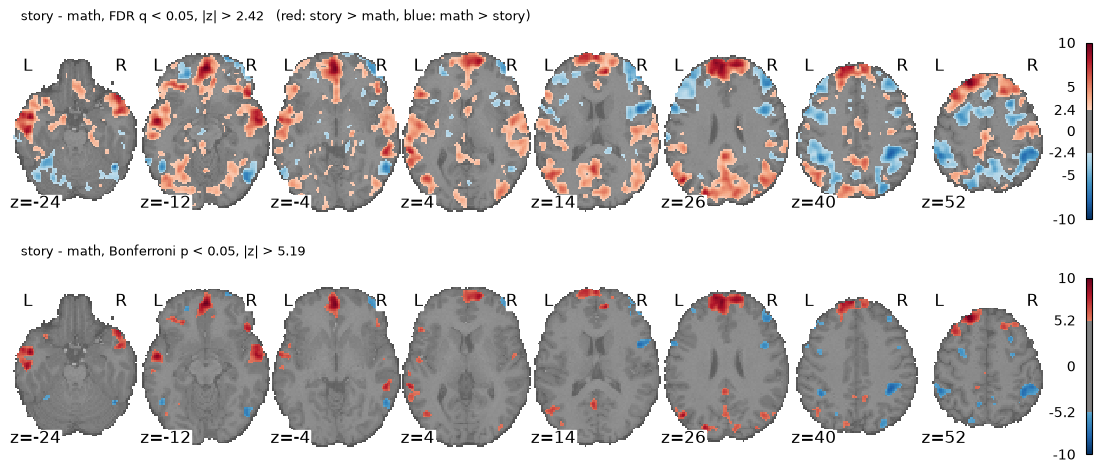

In [26]:
# Figure: story - math contrast, FDR (main map) and Bonferroni
fig, axs = plt.subplots(2, 1, figsize=(14, 5.6))
plot_map(z_sm_thr, thr_sm, f"story - math, FDR q < {FDR_ALPHA}, |z| > {thr_sm:.2f}   (red: story > math, blue: math > story)", axs[0])
plot_map(z_sm_bonf, thr_bonf, f"story - math, Bonferroni p < 0.05, |z| > {thr_bonf:.2f}", axs[1])
fig.savefig(op.join(fig_dir, "7d_contrast_story_minus_math.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3d

Contrast vector: `[-1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]` for `[math, story, rot_x, rot_y, rot_z, trans_x, trans_y, trans_z, drift_1, drift_2, drift_3, drift_4, constant]`. 

**Main map: FDR q < 0.05.** The contrast is very strong (peak z = 10.8). About 72 000 voxels are significant, so the FDR threshold drops to |z| > 2.42. The Bonferroni map (|z| > 5.19) keeps only the core of each region:
- **story > math (red)**: medial prefrontal cortex, bilateral anterior temporal lobes / superior temporal sulcus, angular gyrus, posterior cingulate / precuneus, right posterior cerebellum;
- **math > story (blue)**: bilateral intraparietal sulcus, right precentral / middle frontal gyrus, lateral prefrontal cortex, occipito-temporal cortex, left posterior cerebellum.


## 3e. Regions and functional networks

The story - math map (FDR) is compared with the 7 resting-state networks of Yeo et al. (2011), volumetric version on the MNI 2 mm grid of our fMRI. The atlas is cortical only and covers a thin ribbon, while our data are smoothed with 6 mm, so each brain voxel within 4 mm of the atlas gets the network of its nearest atlas voxel. For each network: **coverage** = % of the network's voxels where story > math (or math > story); **composition** = % of the story > math (or math > story) voxels that fall in this network.

In [27]:
YEO_URL = ("https://raw.githubusercontent.com/ThomasYeoLab/CBIG/master/stable_projects/brain_parcellation/"
           "Yeo2011_fcMRI_clustering/1000subjects_reference/Yeo_JNeurophysiol11_SplitLabels/MNI152/")
YEO_FILE = "Yeo2011_7Networks_N1000.split_components.FSL_MNI152_2mm.nii.gz"
YEO_LUT = "7Networks_ColorLUT_freeview.txt"
for f in (YEO_FILE, YEO_LUT):
    if not op.exists(op.join(atlas_dir, f)):
        urllib.request.urlretrieve(YEO_URL + f, op.join(atlas_dir, f))

# The split atlas has 51 components (e.g. "7Networks_LH_Default_Temp"): grouped into the 7 networks
NETWORKS = {"Vis": "Visual", "SomMot": "Somatomotor", "DorsAttn": "Dorsal attention",
            "SalVentAttn": "Ventral attention / salience", "Limbic": "Limbic", "Cont": "Frontoparietal control",
            "Default": "Default mode"}
NETWORK_COLORS = {"Visual": "#781286", "Somatomotor": "#4682b4", "Dorsal attention": "#00760e",
                  "Ventral attention / salience": "#c43afa", "Limbic": "#b8c96a",     # Yeo's colours (limbic darkened)
                  "Frontoparietal control": "#e69422", "Default mode": "#cd3e4e"}
lut = pd.read_csv(op.join(atlas_dir, YEO_LUT), sep=r"\s+", header=None, usecols=[0, 1], names=["index", "name"])
lut = lut[lut["index"] > 0]
lut["network"] = lut["name"].str.split("_").str[2].map(NETWORKS)

yeo_img = nib.load(op.join(atlas_dir, YEO_FILE))
z_img = z_sm
assert np.allclose(yeo_img.affine, z_img.affine) and yeo_img.shape[:3] == z_img.shape[:3], "atlas not on the fMRI grid"
yeo_split = np.squeeze(yeo_img.get_fdata()).astype(int)

mask_data = nib.load(func_mask).get_fdata() > 0
YEO_DILATION = 2                                                        # voxels (4 mm)
dist, (ii, jj, kk) = ndimage.distance_transform_edt(yeo_split == 0, return_indices=True)
yeo_split = np.where(mask_data & (dist <= YEO_DILATION), yeo_split[ii, jj, kk], yeo_split)
yeo_net = np.full(yeo_split.shape, "", dtype=object)                    # network name of each voxel
for _, row in lut.iterrows():
    yeo_net[yeo_split == row["index"]] = row["network"]
z_data = z_img.get_fdata()
z_fdr = z_sm_thr.get_fdata()
story_vox, math_vox = (z_fdr > 0) & mask_data, (z_fdr < 0) & mask_data

rows = []
for net in NETWORK_COLORS:
    in_net = (yeo_net == net) & mask_data
    rows.append({"network": net, "voxels": int(in_net.sum()),
                 "coverage story>math (%)": 100 * (story_vox & in_net).sum() / in_net.sum(),
                 "coverage math>story (%)": 100 * (math_vox & in_net).sum() / in_net.sum(),
                 "composition story>math (%)": 100 * (story_vox & in_net).sum() / story_vox.sum(),
                 "composition math>story (%)": 100 * (math_vox & in_net).sum() / math_vox.sum()})
outside = (yeo_net == "") & mask_data
rows.append({"network": "outside Yeo (subcortex, cerebellum, WM)", "voxels": int(outside.sum()),
             "coverage story>math (%)": 100 * (story_vox & outside).sum() / outside.sum(),
             "coverage math>story (%)": 100 * (math_vox & outside).sum() / outside.sum(),
             "composition story>math (%)": 100 * (story_vox & outside).sum() / story_vox.sum(),
             "composition math>story (%)": 100 * (math_vox & outside).sum() / math_vox.sum()})
network_table = pd.DataFrame(rows).round(1)
network_table.to_csv(op.join(glm_dir, "networks_story_minus_math.csv"), index=False)
print(network_table.to_string(index=False))

                                network  voxels  coverage story>math (%)  coverage math>story (%)  composition story>math (%)  composition math>story (%)
                                 Visual   30292                     28.6                      3.2                        18.4                         3.9
                            Somatomotor   25890                     32.6                      2.4                        18.0                         2.5
                       Dorsal attention   18437                      7.2                     33.0                         2.8                        24.6
           Ventral attention / salience   17951                      9.9                     14.4                         3.8                        10.4
                                 Limbic   13727                     27.1                      1.3                         7.9                         0.7
                 Frontoparietal control   23165                      5.4    

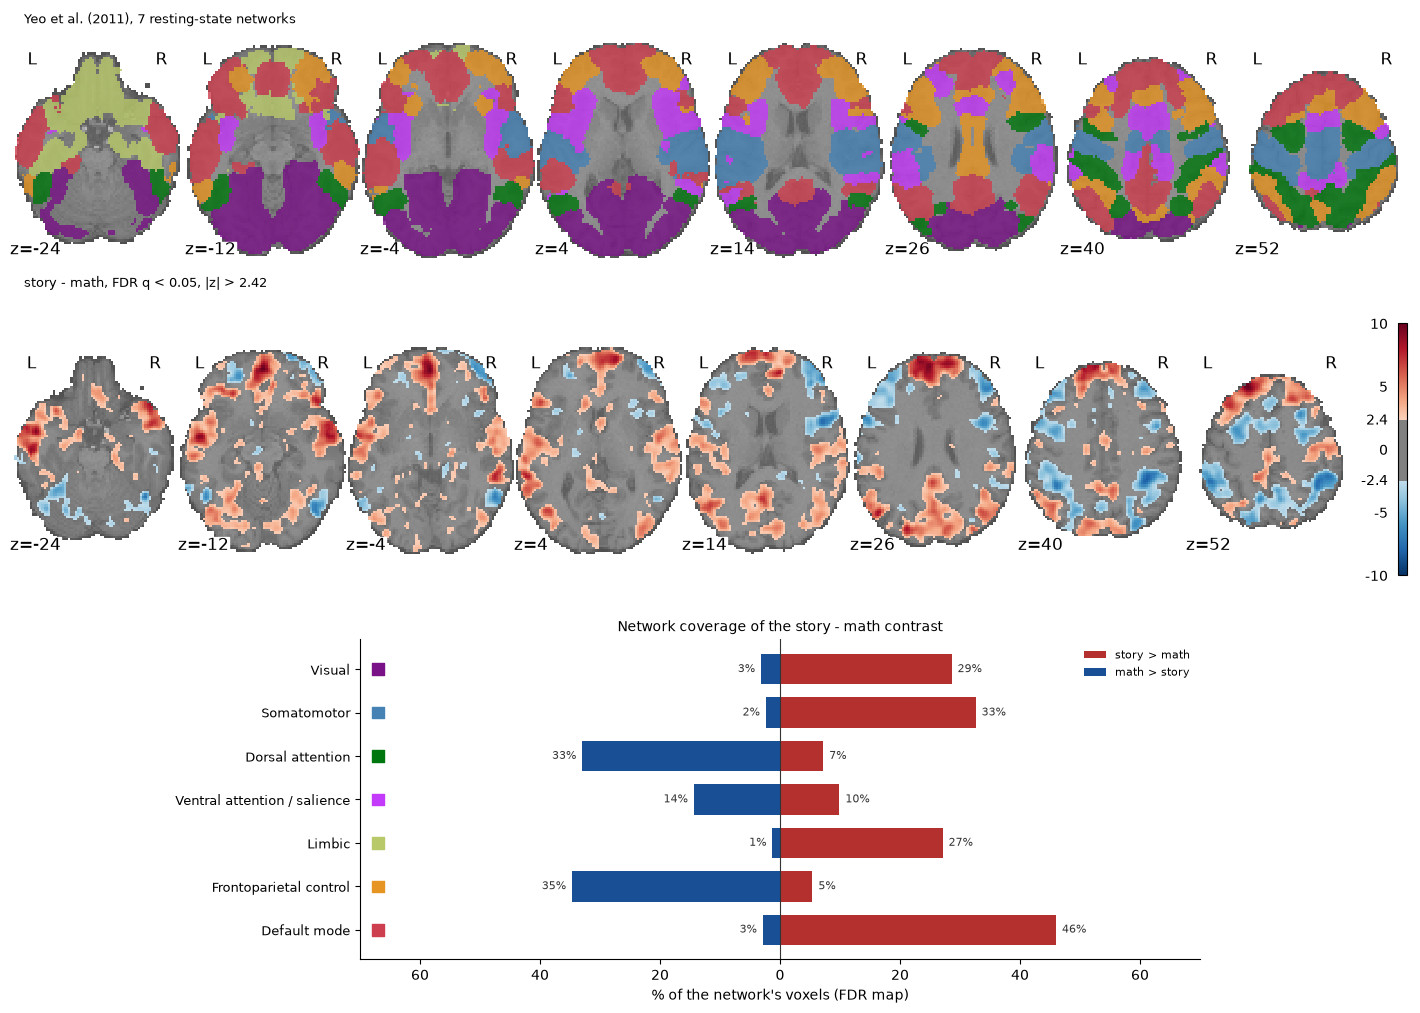

In [28]:
# Figure: Yeo networks on the same axial slices as the contrast, and the network coverage
net_index = np.zeros(yeo_net.shape)
for k, net in enumerate(NETWORK_COLORS, start=1):
    net_index[yeo_net == net] = k
net_img = nib.Nifti1Image(net_index, z_img.affine)
yeo_cmap = ListedColormap(list(NETWORK_COLORS.values()))

fig = plt.figure(figsize=(14, 10))
ax_net = fig.add_axes([0, 0.70, 1, 0.28])
ax_map = fig.add_axes([0, 0.40, 1, 0.28])
ax_bar = fig.add_axes([0.25, 0.03, 0.6, 0.32])
display = plotting.plot_roi(net_img, bg_img=anat_mni, display_mode="z", cut_coords=Z_CUTS, axes=ax_net,
                            cmap=yeo_cmap, vmin=0.5, vmax=7.5, alpha=0.8, black_bg=False, draw_cross=False,
                            colorbar=False)
display.title("Yeo et al. (2011), 7 resting-state networks", size=9, color="black", bgcolor="white")
display = plot_map(z_sm_thr, thr_sm, f"story - math, FDR q < {FDR_ALPHA}, |z| > {thr_sm:.2f}", ax_map)

nt = network_table.iloc[:-1][::-1]                                      # Yeo networks, first one on top
ypos = np.arange(len(nt))
ax_bar.barh(ypos, nt["coverage story>math (%)"], color="#b3302f", height=0.7, label="story > math")
ax_bar.barh(ypos, -nt["coverage math>story (%)"], color="#184f95", height=0.7, label="math > story")
for y, (s, m) in enumerate(zip(nt["coverage story>math (%)"], nt["coverage math>story (%)"])):
    ax_bar.text(s + 1, y, f"{s:.0f}%", va="center", fontsize=8, color="#333333")
    ax_bar.text(-m - 1, y, f"{m:.0f}%", va="center", ha="right", fontsize=8, color="#333333")
ax_bar.set_yticks(ypos, nt["network"], fontsize=9)
ax_bar.set_xlim(-70, 70)
ax_bar.scatter(np.full(len(nt), -67), ypos, marker="s", s=70,                     # network colour, as in the atlas
               c=[NETWORK_COLORS[n] for n in nt["network"]])
ax_bar.axvline(0, color="#333333", lw=0.8)
ax_bar.set_xticks(range(-60, 61, 20), [f"{abs(v)}" for v in range(-60, 61, 20)])
ax_bar.set_xlabel("% of the network's voxels (FDR map)")
ax_bar.set_title("Network coverage of the story - math contrast", fontsize=10)
ax_bar.legend(loc="upper right", frameon=False, fontsize=8)
ax_bar.spines[["top", "right"]].set_visible(False)
fig.savefig(op.join(fig_dir, "7e_networks.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3e

**Math > story: dorsal attention and frontoparietal control networks.** They hold 57% of the math > story voxels, and a third of each network is more active during math (33% and 35% coverage). The intraparietal sulcus holds the representation of numerical quantity, and the frontoparietal network supports working memory and the step-by-step control of mental arithmetic. The posterior cerebellum, outside the atlas, is also more active during math.

**Story > math: default mode network first** (46% coverage, 38% of the story > math voxels): medial prefrontal cortex, posterior cingulate / precuneus, angular gyrus and lateral temporal cortex. This is the overlap between the default mode network and the semantic network: understanding a narrative uses internally directed, memory-based thinking, whereas the effortful math task deactivates these regions. The limbic, somatomotor and visual networks are also more active during the stories.

## 3f. Semantic language regions

Binder et al. (2011) designed the story vs math contrast to map the **anterior temporal lobe (ATL)**. The regions expected for story > math are: the ATL (temporal pole, anterior STG / MTG and the **ventral ATL**: anterior inferior temporal, fusiform and parahippocampal gyri), the posterior MTG and angular gyrus, the inferior frontal gyrus, the medial prefrontal cortex and the posterior cingulate. For each region (Harvard-Oxford, left and right) we report the % of its voxels where story > math, the peak z, and the temporal SNR (mean / std over time) of the unsmoothed run, which tells whether the region could be detected at all.

In [29]:
BINDER_ROIS = {                                       # Harvard-Oxford cortical label -> short name
    "Temporal Pole": "temporal pole",
    "Superior Temporal Gyrus, anterior division": "ant. STG",
    "Middle Temporal Gyrus, anterior division": "ant. MTG",
    "Inferior Temporal Gyrus, anterior division": "ant. ITG (ventral ATL)",
    "Temporal Fusiform Cortex, anterior division": "ant. fusiform (ventral ATL)",
    "Parahippocampal Gyrus, anterior division": "ant. parahippocampal (ventral ATL)",
    "Middle Temporal Gyrus, posterior division": "post. MTG",
    "Angular Gyrus": "angular gyrus",
    "Inferior Frontal Gyrus, pars triangularis": "IFG triangularis",
    "Frontal Orbital Cortex": "orbitofrontal / IFG orbitalis",
    "Superior Frontal Gyrus": "dorsomedial PFC (SFG)",
    "Frontal Medial Cortex": "ventromedial PFC",
    "Cingulate Gyrus, posterior division": "posterior cingulate",
}

ho_cort = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
ho_cort_data = np.squeeze(image.resample_to_img(ho_cort.maps, z_img, interpolation="nearest").get_fdata()).astype(int)

# Temporal SNR of the motion-corrected run before smoothing (part 1-2)
mc_data = nib.load(func_mc_brain).get_fdata(dtype=np.float32)
mc_mean, mc_std = mc_data.mean(axis=3), mc_data.std(axis=3)
tsnr = np.divide(mc_mean, mc_std, out=np.zeros_like(mc_mean), where=mc_std > 0)
del mc_data
mni_brain_mask = datasets.load_mni152_brain_mask(resolution=2)            # whole-brain reference (MNI)
mni_vox = np.squeeze(image.resample_to_img(mni_brain_mask, z_img, interpolation="nearest").get_fdata()) > 0
tsnr_brain = np.median(tsnr[mask_data])

x_mm = z_img.affine[0, 0] * np.arange(z_img.shape[0]) + z_img.affine[0, 3]   # MNI x of each voxel column
left = np.broadcast_to(x_mm[:, None, None] < 0, z_img.shape[:3])

rows = []
for ho_label, short in BINDER_ROIS.items():
    roi_all = ho_cort_data == ho_cort.labels.index(ho_label)
    for side, hemi in (("L", left), ("R", ~left)):
        roi = roi_all & hemi & mni_vox
        roi_in = roi & mask_data
        rows.append({"region": short, "side": side,
                     "story>math (%)": 100 * (story_vox & roi).sum() / roi.sum(),
                     "peak z": z_data[roi_in].max() if roi_in.any() else np.nan,
                     "median tSNR": np.median(tsnr[roi_in]) if roi_in.any() else 0})
binder_table = pd.DataFrame(rows).round(1)
binder_table.to_csv(op.join(glm_dir, "binder_regions_story_minus_math.csv"), index=False)
print(f"Median tSNR of the brain: {tsnr_brain:.1f}")
print(binder_table.to_string(index=False))

[fetch_atlas_harvard_oxford] Dataset directory found: /Users/valentinmarbach/nilearn_data/fsl


Median tSNR of the brain: 32.6
                            region side  story>math (%)  peak z  median tSNR
                     temporal pole    L            63.5     7.9    24.900000
                     temporal pole    R            56.3     8.3    25.700001
                          ant. STG    L            99.6    10.2    36.599998
                          ant. STG    R            92.2     8.8    35.299999
                          ant. MTG    L            93.0     9.2    34.200001
                          ant. MTG    R            71.8     8.8    32.400002
            ant. ITG (ventral ATL)    L            27.3     6.4    24.900000
            ant. ITG (ventral ATL)    R            24.6     6.6    26.200001
       ant. fusiform (ventral ATL)    L            33.8     4.6    19.200001
       ant. fusiform (ventral ATL)    R            11.6     4.1    23.900000
ant. parahippocampal (ventral ATL)    L            21.5     5.6    14.300000
ant. parahippocampal (ventral ATL)    R      

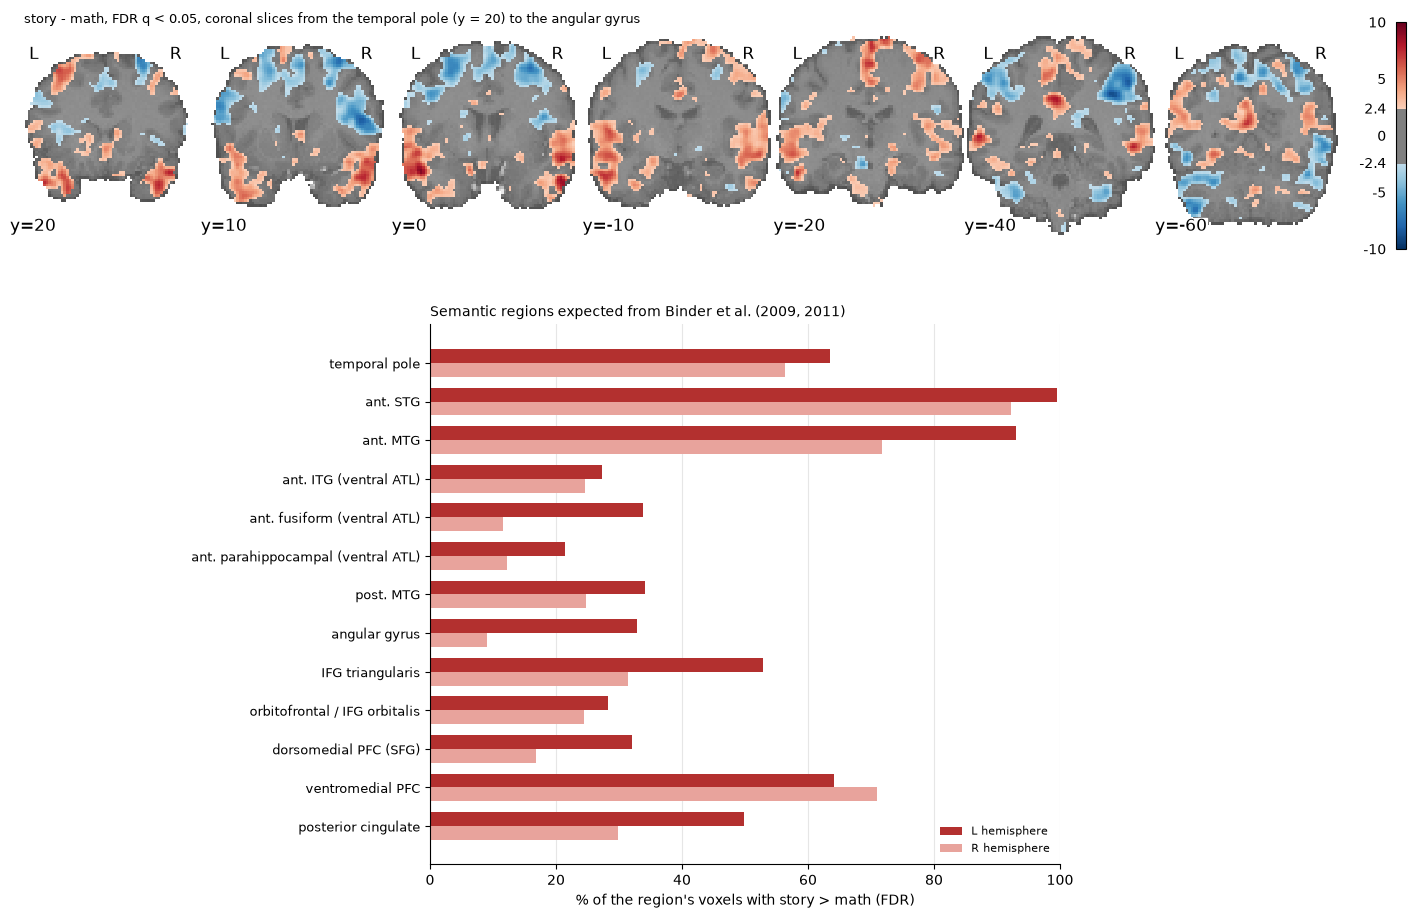

In [30]:
# Figure: coronal slices through the ATL, and the % of each expected region with story > math
Y_CUTS = [20, 10, 0, -10, -20, -40, -60]                                 # temporal pole -> angular gyrus
fig = plt.figure(figsize=(14, 9))
ax_c = fig.add_axes([0, 0.70, 1, 0.28])
ax_r = fig.add_axes([0.3, 0.03, 0.45, 0.6])
display = plotting.plot_stat_map(z_sm_thr, bg_img=anat_mni, display_mode="y", cut_coords=Y_CUTS, axes=ax_c,
                                 threshold=thr_sm, vmax=Z_VMAX, cmap="RdBu_r", black_bg=False, draw_cross=False)
display.title(f"story - math, FDR q < {FDR_ALPHA}, coronal slices from the temporal pole (y = 20) to the angular gyrus",
              size=9, color="black", bgcolor="white")

regions = list(BINDER_ROIS.values())[::-1]
ypos = np.arange(len(regions))
bt = binder_table.set_index(["region", "side"])
for side, color, dy in (("L", "#b3302f", 0.18), ("R", "#e8a39c", -0.18)):    # left darker: expected dominant side
    ax_r.barh(ypos + dy, [bt.loc[(r, side), "story>math (%)"] for r in regions], height=0.36, color=color,
              label=f"{side} hemisphere")
ax_r.set_yticks(ypos, regions, fontsize=9)
ax_r.set(xlim=(0, 100), xlabel="% of the region's voxels with story > math (FDR)")
ax_r.set_title("Semantic regions expected from Binder et al. (2009, 2011)", fontsize=10, loc="left")
ax_r.legend(loc="lower right", frameon=False, fontsize=8)
ax_r.spines[["top", "right"]].set_visible(False)
ax_r.grid(axis="x", color="0.9")
ax_r.set_axisbelow(True)
fig.savefig(op.join(fig_dir, "7f_semantic_regions.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3f

**The expected semantic regions are present**, in both hemispheres: the lateral ATL (anterior STG L 99.6%, peak z 10.2; anterior MTG L 93%; temporal pole 56-64%), the posterior MTG, the left angular gyrus, the left IFG pars triangularis (53%), the ventromedial PFC (64-71%) and the posterior cingulate. The left side dominates in most regions, as expected for language, but the ATL is strongly bilateral.

**The ventral ATL is the weak spot** Possible reasons:
1. **Susceptibility artefacts.** The ventral ATL lies just above the air-filled sinuses and ear canals, which cause signal dropout in gradient-echo EPI. 
2. **The contrast removes what is shared.** The math problems are also spoken sentences that must be understood, so the subtraction cancels the shared auditory, phonological, syntactic and part of the semantic processing.
3. **one subject and one 3.75-min run (low power)**, and the 6 mm smoothing, which mixes the thin ventral cortex with the low-signal voxels next to it.

# Part 2. Temporal K-means (variant 3)

## 1. Temporal K-means

**Samples and features.** As in lab 7, each timepoint (fMRI volume) is one sample and each brain voxel is one feature: X has 313 rows and ~234 000 columns (voxels of the functional mask). Each cluster is a recurring brain "state", and its centroid (the mean pattern of its timepoints) is a spatial map.

**Normalisation.** Lab 7 removes the mean of each voxel, so that the clustering sees the fluctuations and not the anatomy. We also divide by the standard deviation (z-score), so that a few very variable voxels (vessels, brain edges) do not dominate the Euclidean distance. 

In [31]:
mask_img = nib.load(func_mask)
X_raw = nib.load(func_img_path).get_fdata(dtype=np.float32)[mask_data].T  # timepoints x voxels
print(f"X: {X_raw.shape[0]} timepoints x {X_raw.shape[1]} voxels")

X = signal.clean(X_raw, detrend=False, standardize="zscore_sample")  # demean (lab 7) + unit variance per voxel

# Exact low-dimensional coordinates of the timepoints (same pairwise distances as in voxel space)
U, S, _ = np.linalg.svd(X, full_matrices=False)
X_red = U * S                                                         # timepoints x 313
assert np.allclose(np.linalg.norm(X_red[0] - X_red[1]), np.linalg.norm(X[0] - X[1]), rtol=1e-3)
del X_raw

X: 313 timepoints x 234273 voxels


## 2. Number of clusters

Three criteria, for K = 2 ... 20: **inertia** (elbow criterion of lab 7); **silhouette** (how much closer each timepoint is to its own cluster than to the next one); **stability** across 10 random seeds

In [32]:
K_RANGE = range(2, 21)
N_SEEDS = 10
N_INIT = 20

rows = []
for k in K_RANGE:
    ref = KMeans(n_clusters=k, random_state=0, n_init=N_INIT).fit(X_red)
    ari = [adjusted_rand_score(ref.labels_, KMeans(n_clusters=k, random_state=s, n_init=N_INIT).fit(X_red).labels_)
           for s in range(1, N_SEEDS + 1)]
    rows.append({"K": k, "inertia": ref.inertia_, "silhouette": silhouette_score(X_red, ref.labels_),
                 "stability (ARI)": np.mean(ari), "stability sd": np.std(ari)})
k_table = pd.DataFrame(rows)
k_table.to_csv(op.join(km_dir, "choice_of_K.csv"), index=False)
print(k_table.round(3).to_string(index=False))

 K    inertia  silhouette  stability (ARI)  stability sd
 2 66933096.0       0.078            0.989         0.017
 3 63820276.0       0.057            0.956         0.036
 4 61078072.0       0.066            0.956         0.033
 5 59286204.0       0.069            0.887         0.051
 6 58262004.0       0.059            0.668         0.058
 7 57126176.0       0.052            0.718         0.087
 8 56173788.0       0.055            0.703         0.055
 9 55228176.0       0.055            0.721         0.054
10 54905368.0       0.047            0.691         0.049
11 53888096.0       0.055            0.643         0.053
12 53853712.0       0.049            0.573         0.041
13 52916776.0       0.052            0.584         0.042
14 52572720.0       0.041            0.567         0.038
15 52210968.0       0.042            0.494         0.021
16 51816408.0       0.037            0.525         0.056
17 51121648.0       0.038            0.482         0.033
18 50827368.0       0.040      

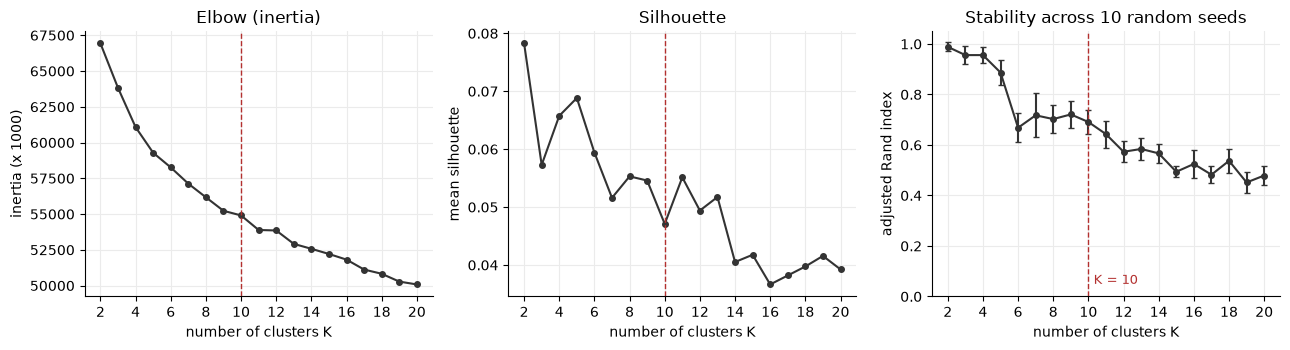

In [33]:
K = 10                                              # chosen number of clusters (see the comments below)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].plot(k_table["K"], k_table["inertia"] / 1e3, "o-", color="#333333", ms=4)
axs[0].set(xlabel="number of clusters K", ylabel="inertia (x 1000)", title="Elbow (inertia)")
axs[1].plot(k_table["K"], k_table["silhouette"], "o-", color="#333333", ms=4)
axs[1].set(xlabel="number of clusters K", ylabel="mean silhouette", title="Silhouette")
axs[2].errorbar(k_table["K"], k_table["stability (ARI)"], yerr=k_table["stability sd"], fmt="o-",
                color="#333333", ms=4, capsize=2)
axs[2].set(xlabel="number of clusters K", ylabel="adjusted Rand index", ylim=(0, 1.05),
           title=f"Stability across {N_SEEDS} random seeds")
for ax in axs:
    ax.axvline(K, color="#b3302f", ls="--", lw=1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="0.92")
    ax.set_xticks(range(2, 21, 2))
axs[2].text(K + 0.3, 0.05, f"K = {K}", color="#b3302f", fontsize=9)
fig.tight_layout()
fig.savefig(op.join(fig_dir, "8a_choice_of_K.png"), dpi=FIG_DPI)
plt.show()

In [34]:
# Final clustering, with many initialisations to get the best solution
kmeans = KMeans(n_clusters=K, random_state=0, n_init=200).fit(X_red)

# Clusters ordered by size (number of timepoints), largest first: "the first 10 clusters" = all of them here
sizes = np.bincount(kmeans.labels_, minlength=K)
order = np.argsort(-sizes)
labels = np.argsort(order)[kmeans.labels_]                            # relabel: 0 = largest cluster
sizes = sizes[order]

# Centroids in voxel space: mean z-scored pattern of the timepoints of each cluster
centroids = np.stack([X[labels == c].mean(axis=0) for c in range(K)])  # K x voxels
centroid_data = np.zeros(mask_data.shape + (K,), dtype=np.float32)
centroid_data[mask_data] = centroids.T
centroid_img = nib.Nifti1Image(centroid_data, mask_img.affine)
centroid_img.to_filename(op.join(km_dir, f"centroids_K{K}.nii.gz"))
np.savetxt(op.join(km_dir, f"labels_K{K}.txt"), labels, fmt="%d")
print("Timepoints per cluster:", dict(enumerate(sizes)))

Timepoints per cluster: {0: np.int64(48), 1: np.int64(43), 2: np.int64(42), 3: np.int64(35), 4: np.int64(31), 5: np.int64(30), 6: np.int64(27), 7: np.int64(24), 8: np.int64(23), 9: np.int64(10)}


### Comments on the choice of K (`8a`)

The inertia decreases smoothly with K. The silhouette is low for every K (0.04-0.08): fMRI timepoints do not form well separated groups, so any partition cuts through a continuum. The stability is high for K ≤ 5, stays on a plateau around 0.70 for K = 6-10, and drops beyond. We choose **K = 10**, the finest partition that is still reproducible; K ≤ 5 is too coarse and merges the task states with the slow fluctuations.

### Centroid maps

Each centroid is shown on the T1 in MNI, in units of standard deviation of each voxel: red = above the voxel's mean during the cluster, blue = below (|z| < 0.3 not coloured).

In [35]:
z_glm = z_sm.get_fdata()[mask_data]
r_glm = np.array([np.corrcoef(centroids[c], z_glm)[0, 1] for c in range(K)])

# Mean centroid value in each Yeo network (same dilated atlas as in 3e)
yeo_vox = yeo_net[mask_data]
net_means = pd.DataFrame({net: centroids[:, yeo_vox == net].mean(axis=1) for net in NETWORK_COLORS},
                         index=[f"C{c + 1}" for c in range(K)])
net_means.to_csv(op.join(km_dir, f"centroid_network_means_K{K}.csv"))
summary = pd.DataFrame({"cluster": [f"C{c + 1}" for c in range(K)], "timepoints": sizes,
                        "% of run": np.round(100 * sizes / n_scans, 1),
                        "r with story-math map": r_glm.round(2),
                        "top network (+)": net_means.idxmax(axis=1).values,
                        "bottom network (-)": net_means.idxmin(axis=1).values})
summary.to_csv(op.join(km_dir, f"cluster_summary_K{K}.csv"), index=False)
print(summary.to_string(index=False))

cluster  timepoints  % of run  r with story-math map        top network (+)           bottom network (-)
     C1          48      15.3                   0.35                 Limbic             Dorsal attention
     C2          43      13.7                   0.32           Default mode       Frontoparietal control
     C3          42      13.4                  -0.71 Frontoparietal control                 Default mode
     C4          35      11.2                  -0.16 Frontoparietal control                  Somatomotor
     C5          31       9.9                   0.21                 Visual                       Limbic
     C6          30       9.6                  -0.05                 Limbic             Dorsal attention
     C7          27       8.6                  -0.24       Dorsal attention                       Limbic
     C8          24       7.7                  -0.24                 Limbic                       Visual
     C9          23       7.3                   0.27   

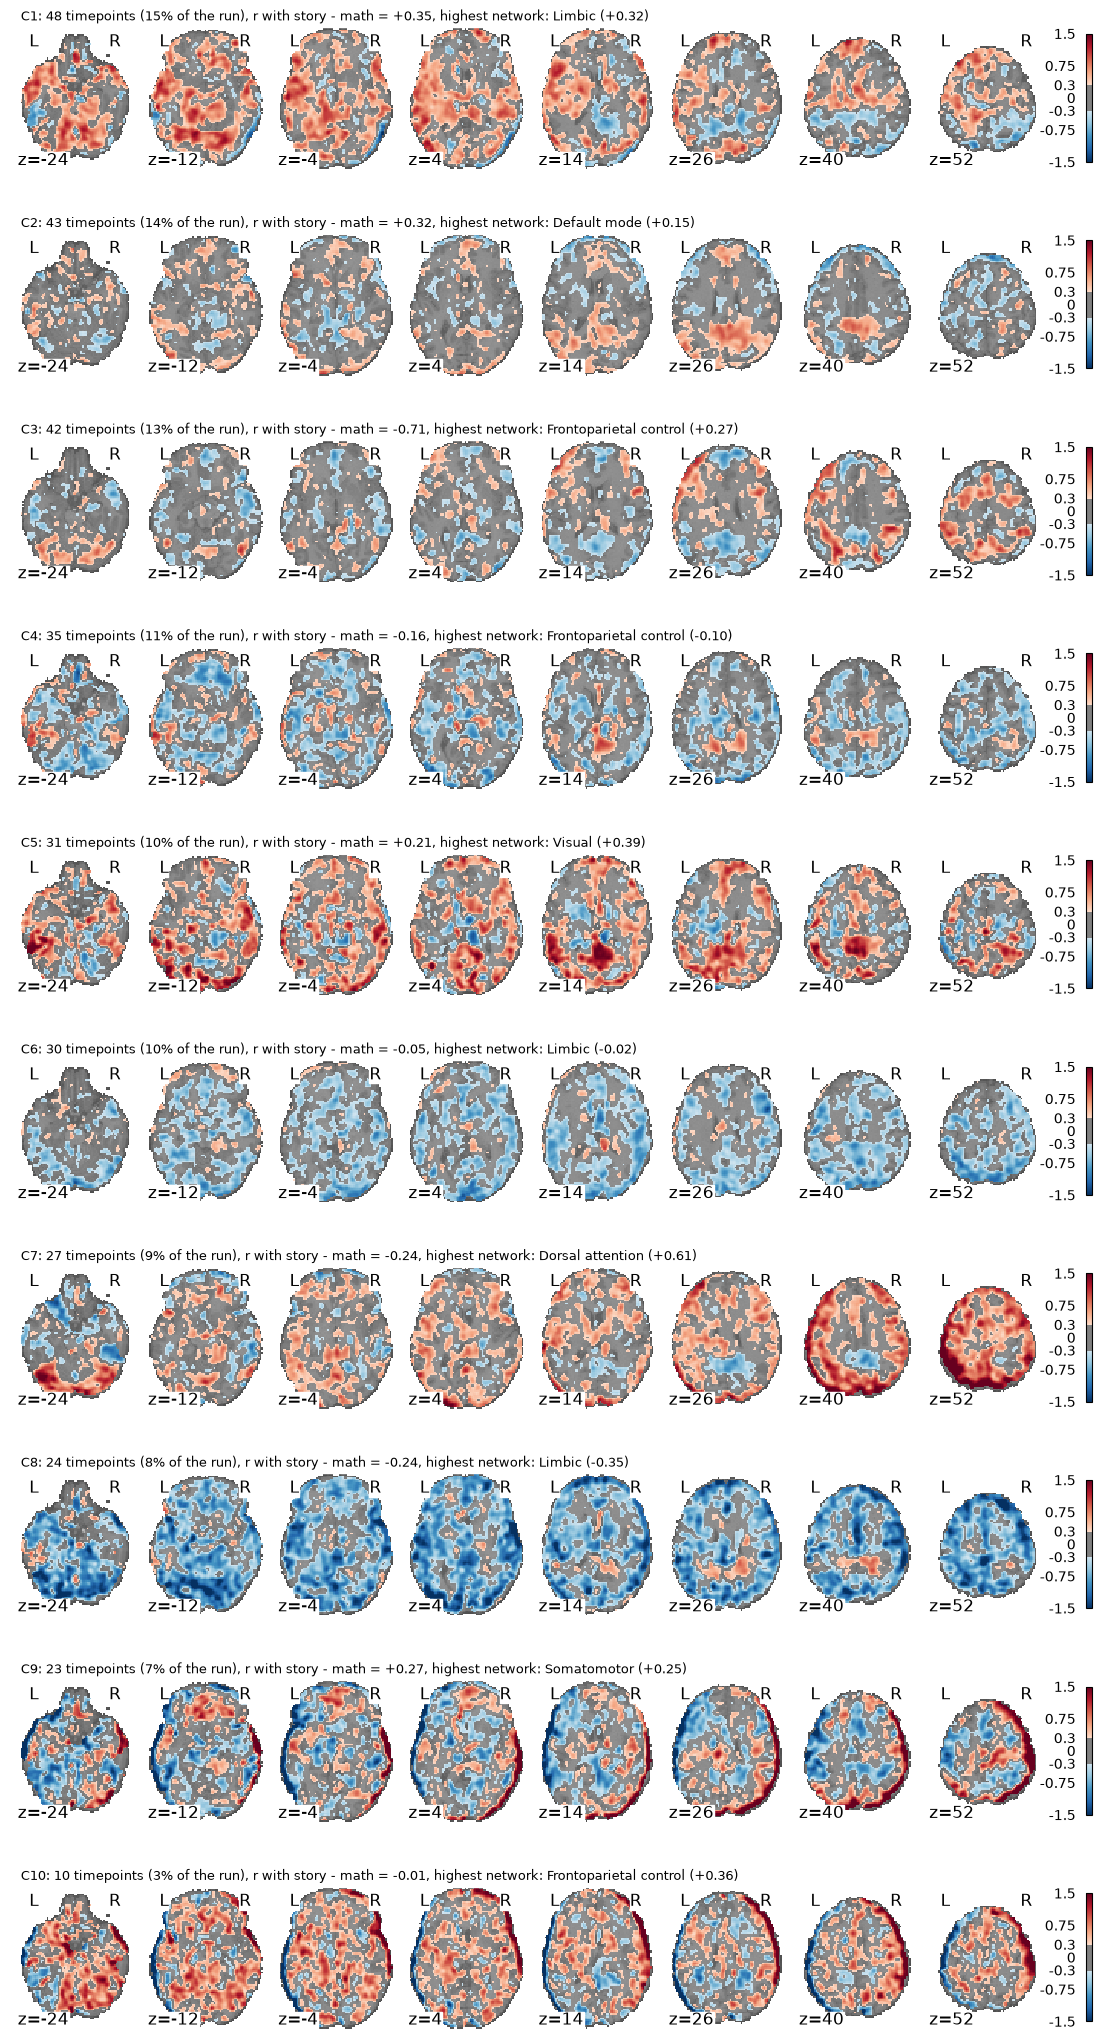

In [36]:
VMAX = 1.5
fig, axs = plt.subplots(K, 1, figsize=(14, 2.6 * K), gridspec_kw={"hspace": 0.45})
for c, ax in enumerate(axs):
    display = plotting.plot_stat_map(image.index_img(centroid_img, c), bg_img=anat_mni, display_mode="z",
                                     cut_coords=Z_CUTS, axes=ax, threshold=0.3, vmax=VMAX, cmap="RdBu_r",
                                     black_bg=False, draw_cross=False)
    display.title(f"C{c + 1}: {sizes[c]} timepoints ({100 * sizes[c] / n_scans:.0f}% of the run), "
                  f"r with story - math = {r_glm[c]:+.2f}, "
                  f"highest network: {summary['top network (+)'][c]} ({net_means.iloc[c].max():+.2f})",
                  y=1.12, size=9, color="black", bgcolor="white")  # above the slices, not over the L/R labels
fig.savefig(op.join(fig_dir, "8b_centroid_maps.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

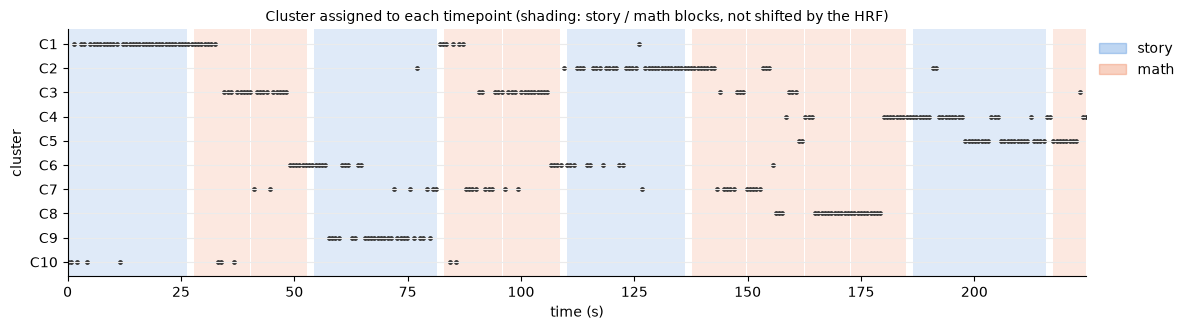

In [37]:
# Figure: cluster of each timepoint over the run, with the story and math blocks
fig, ax = plt.subplots(figsize=(12, 3.4))
for _, ev in events[events["trial_type"].isin(["story", "math"])].iterrows():
    color = STORY_COLOR if ev["trial_type"] == "story" else MATH_COLOR
    ax.axvspan(ev["onset"], ev["onset"] + ev["duration"], color=color, alpha=0.15, lw=0)
ax.scatter(frame_times, labels + 1, c="#333333", s=6)
ax.set(xlabel="time (s)", ylabel="cluster", xlim=(0, frame_times[-1]), ylim=(K + 0.6, 0.4))
ax.set_yticks(range(1, K + 1), [f"C{c}" for c in range(1, K + 1)])
ax.set_title("Cluster assigned to each timepoint (shading: story / math blocks, not shifted by the HRF)", fontsize=10)
ax.legend(handles=[Patch(color=STORY_COLOR, alpha=0.3, label="story"), Patch(color=MATH_COLOR, alpha=0.3, label="math")],
          loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92")
fig.tight_layout()
fig.savefig(op.join(fig_dir, "8c_cluster_time_course.png"), dpi=FIG_DPI)
plt.show()

## 3. Cluster time courses vs GLM regressors

For each of the first 10 clusters (here all of them, ordered by size), the binary time course (1 at the timepoints of the cluster, 0 elsewhere) is correlated with the GLM regressors of part 1-3: the block and event task regressors, and the motion and drift regressors, to detect clusters driven by nuisance rather than by the task. fMRI timepoints are autocorrelated, so the correlations are read by their size rather than a p-value.

In [38]:
regressors = pd.concat([dm_block[BLOCK_CONDITIONS], dm_event[EVENT_CONDITIONS],
                        dm_block[motion_names[:6] + drift_cols]], axis=1)
binary = pd.DataFrame({f"C{c + 1}": (labels == c).astype(float) for c in range(K)})
corr = pd.DataFrame([[np.corrcoef(binary[b], regressors[r])[0, 1] for r in regressors] for b in binary],
                    index=binary.columns, columns=regressors.columns)
corr.to_csv(op.join(km_dir, f"correlation_clusters_regressors_K{K}.csv"))
print(corr.round(2).to_string())

     story  math  present_story  question_story  response_story  present_math  question_math  response_math   cue  rot_x  rot_y  rot_z  trans_x  trans_y  trans_z  drift_1  drift_2  drift_3  drift_4
C1    0.33 -0.36           0.16            0.20            0.22         -0.25          -0.25          -0.25 -0.02  -0.35  -0.05   0.19     0.11     0.30    -0.17     0.52     0.37     0.29     0.25
C2    0.22 -0.23           0.13            0.14            0.10         -0.24          -0.16          -0.03  0.12   0.26   0.05   0.04     0.05    -0.37    -0.16    -0.14    -0.43     0.30     0.22
C3   -0.43  0.47          -0.30           -0.19           -0.15          0.48           0.24           0.17 -0.12  -0.19   0.03   0.10     0.14     0.20     0.04     0.17    -0.15    -0.08    -0.03
C4   -0.06  0.07          -0.02           -0.05           -0.09          0.02           0.10           0.04  0.06   0.13   0.23  -0.12     0.20     0.26    -0.15    -0.44     0.27    -0.06    -0.11
C5    0.26

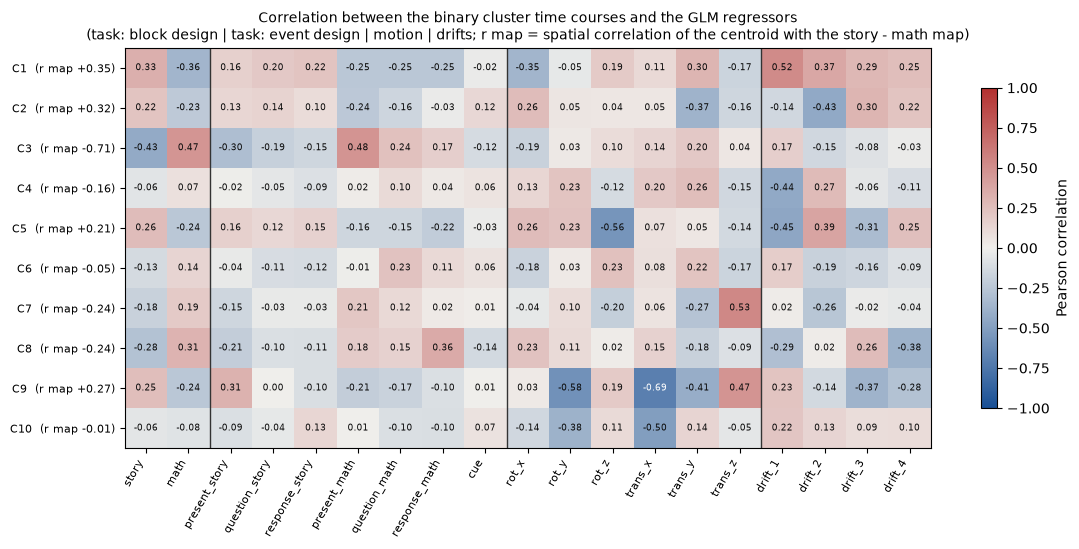

In [39]:
fig, ax = plt.subplots(figsize=(13, 5.2))
im = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(corr.shape[1]), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(K), [f"{c}  (r map {r:+.2f})" for c, r in zip(corr.index, r_glm)], fontsize=8)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
for x in (1.5, 8.5, 14.5):                                             # block | event | motion | drift
    ax.axvline(x, color="#333333", lw=1)
ax.set_title("Correlation between the binary cluster time courses and the GLM regressors\n"
             "(task: block design | task: event design | motion | drifts; r map = spatial correlation of the "
             "centroid with the story - math map)", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
fig.savefig(op.join(fig_dir, "8d_correlation_clusters_regressors.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on the centroid maps and on point 3 (`8b`, `8c`, `8d`)

**Task states.**
- **C3 = math state.** The only cluster that comes back with the task: the first three pairs of math blocks. Its centroid is positive in the intraparietal sulcus and lateral prefrontal cortex and negative in the posterior cingulate / precuneus: the mirror image of the GLM contrast (spatial r = -0.71 with story - math). Its time course correlates with `math` (0.47).
- **C1 and C2 = story states.** C1 covers the first story block, C2 the third one. Both centroids correlate positively with the story - math map (+0.35, +0.32) and with `story` (0.33, 0.22). C2 is highest in the default mode network; C1 is positive almost everywhere, closer to a global increase at the start of the run. Each covers a single block, so they also follow the slow drifts (C1 with `drift_1` 0.52, C2 with `drift_2` -0.43).

**Nuisance states.**
- **C9 and C10 = motion**: strong values of opposite signs along opposite edges of the brain, the signature of a small head displacement; time courses correlated with `trans_x` (-0.69, -0.50).
- **C7 and C8 = global signal**: positive (C7) or negative (C8) almost everywhere, as with breathing, arousal or motion; C7 correlates with `trans_z` (0.53).
- **C4, C5, C6**: segments at the end of the run and at the math-to-story transitions, correlated with the drifts and motion.

**Relation with the GLM.** Without knowing the task, K-means finds the two sides of the story - math contrast: the frontoparietal "math" state (C3) and the default-mode "story" states (C1, C2). But they explain only part of the run, and the other clusters are dominated by drift, global signal and motion. The GLM separates these sources because it models them explicitly. K-means has no such model, and its clusters must be interpreted afterwards, as done here.